# GNN Project — GCN & GAT for next-period category recommendation

**Task.** Given a customer's purchases up to period *t*, predict which product categories they buy in *t+1*. Output: a customer × category probability matrix (multi-label link prediction on a customer–item bipartite graph).

**Working style.** One cell at a time: a markdown *what & why* cell before each code cell, an **Insight** cell after each result. Each phase ends with a report before continuing.



**This is a training notebook for the SC4020 group project**, using the EuroMart Retail dataset. It is intended for learning and experimentation, not as a finished or production-ready analysis.

**Contents**

Data cleaning: preprocessing steps applied to the raw EuroMart Retail data before model training.
EDA: exploratory data analysis of the cleaned data. A cleaned-up version of these results is in EDA_DS1_Euromart for easier reference.
GCN model: a Graph Convolutional Network for next-period purchase prediction. A cleaned-up version of these results is in GCN_DS1_Euromart for easier reference.
GAT model: a Graph Attention Network for the same task. The GAT insights in this notebook are the ones used in the group report.

The EDA and GCN notebooks present results from this notebook in a tidier form. If anything differs, this notebook is the reference for the GAT results in the report.

## Experiment Log

*Validation set (targets 2013Q4–2014Q1, 445 customers). Adoption rule: change kept only if val Recall@10 improves by ≥ 0.01. Reference: Popularity R@10 0.711 / NDCG@10 0.456 / PR-AUC 0.186.*

| Round | Model | Change | Val Recall@10 | Val NDCG@10 | Val PR-AUC | Conclusion |
|---|---|---|---|---|---|---|
| R1 | GCN | baseline (2L, d64, drop .3, lr 1e-3) | 0.7474 | 0.4506 | 0.1848 | reference |
| R2 | GCN | edge_weight = log(1+#orders) | 0.7485 | 0.4506 | 0.1840 | no gain (+0.001) -> keep unweighted |
| R3 | GCN | layers = 1 | 0.7205 | 0.4529 | 0.1798 |  |
| R3 | GCN | layers = 3 | 0.7088 | 0.4386 | 0.1804 |  |
| R3 | GCN | layers = 4 | 0.7250 | 0.4436 | 0.1749 | no gain >= .01 -> keep 2 layers |
| R4 | GCN | hidden = 32 | 0.7443 | 0.4460 | 0.1795 |  |
| R4 | GCN | hidden = 128 | 0.7547 | 0.4565 | 0.1843 | +0.007 < .01 -> keep d=64 |
| R5 | GCN | dropout = 0.0 | 0.7634 | 0.4537 | 0.1848 |  |
| R5 | GCN | dropout = 0.1 | 0.7629 | 0.4556 | 0.1848 |  |
| R5 | GCN | dropout = 0.5 | 0.7118 | 0.4404 | 0.1788 | +0.016 -> adopt dropout 0 |
| R6 | GCN | weight decay = 1e-06 | 0.7621 | 0.4536 | 0.1852 |  |
| R6 | GCN | weight decay = 1e-05 | 0.7629 | 0.4568 | 0.1827 |  |
| R6 | GCN | weight decay = 0.0001 | 0.7646 | 0.4552 | 0.1848 |  |
| R6 | GCN | weight decay = 0.001 | 0.7174 | 0.4378 | 0.1776 | wd<=1e-4 no gain, 1e-3 hurts -> keep 0 |
| R7 | GCN | learning rate = 0.0003 | 0.7687 | 0.4579 | 0.1829 |  |
| R7 | GCN | learning rate = 0.003 | 0.7565 | 0.4597 | 0.1864 | adopted lr 0.001 |
| G1 | GAT | baseline (2L, 4 heads, d64, att-drop .1) | 0.7778 | 0.4749 | 0.1880 | GAT reference |
| G2 | GAT | heads = 1 | 0.7628 | 0.4630 | 0.1786 |  |
| G2 | GAT | heads = 2 | 0.7691 | 0.4782 | 0.1842 |  |
| G2 | GAT | heads = 8 | 0.7532 | 0.4640 | 0.1779 | best heads=4 gain +0.000 -> adopt 4 |
| G3 | GAT | layers = 1 | 0.7404 | 0.4549 | 0.1827 |  |
| G3 | GAT | layers = 3 | 0.7541 | 0.4533 | 0.1799 | best layers=2 gain +0.000 -> adopt 2 |
| G4 | GAT | att_dropout = 0.0 | 0.7778 | 0.4631 | 0.1824 |  |
| G4 | GAT | att_dropout = 0.3 | 0.7778 | 0.4611 | 0.1787 | best att_dropout=0.1 gain +0.000 -> adopt 0.1 |
| G5 | GAT | dropout = 0.1 | 0.7829 | 0.4627 | 0.1801 |  |
| G5 | GAT | dropout = 0.3 | 0.7803 | 0.4767 | 0.1868 |  |
| G5 | GAT | dropout = 0.5 | 0.7614 | 0.4567 | 0.1795 | best dropout=0.1 gain +0.005 -> adopt 0.0 |
| G6 | GAT | wd = 1e-06 | 0.7779 | 0.4559 | 0.1832 |  |
| G6 | GAT | wd = 1e-05 | 0.7794 | 0.4738 | 0.1879 |  |
| G6 | GAT | wd = 0.0001 | 0.7803 | 0.4760 | 0.1839 |  |
| G6 | GAT | wd = 0.001 | 0.7875 | 0.4627 | 0.1804 | best wd=0.001 gain +0.010 -> adopt 0.0 |

**Final TEST results (targets 2014Q2–Q4, 872 customer-quarters; mean ± std over 5 seeds):**

| Model | Test Recall@10 | Test NDCG@10 | Test PR-AUC | Params | Verdict vs Popularity (gap > seed std) |
|---|---|---|---|---|---|
| Popularity | 0.7246 ± 0.0000 | 0.4748 ± 0.0000 | 0.2061 ± 0.0000 | 17 | reference |
| Repeat-last-period | 0.7079 ± 0.0000 | 0.4309 ± 0.0000 | 0.1773 ± 0.0000 | 0 | WORSE / WORSE / WORSE |
| Repeat-frequent | 0.7077 ± 0.0000 | 0.4356 ± 0.0000 | 0.1858 ± 0.0000 | 0 | WORSE / WORSE / WORSE |
| LogReg | 0.7225 ± 0.0000 | 0.4730 ± 0.0000 | 0.2083 ± 0.0000 | 38 | WORSE / WORSE / BETTER |
| MLP | 0.7131 ± 0.0100 | 0.4668 ± 0.0115 | 0.1878 ± 0.0065 | 2,497 | WORSE / no difference / WORSE |
| GCN | 0.7128 ± 0.0036 | 0.4668 ± 0.0016 | 0.2002 ± 0.0064 | 10,368 | WORSE / WORSE / no difference |
| GAT | 0.7098 ± 0.0106 | 0.4581 ± 0.0099 | 0.1969 ± 0.0065 | 23,296 | WORSE / WORSE / WORSE |

## Phase 0 — Setup

**What:** check which libraries are installed (torch, torch_geometric, sklearn, pandas, matplotlib, seaborn, umap-learn), plus the Python version and whether a GPU is available.

**Why:** decides whether I can use PyTorch Geometric's `GCNConv`/`GATConv` or need to write the layers by hand with sparse adjacency. I check with `importlib` first so nothing crashes on a missing package.

In [25]:
import sys, platform, importlib
print('Python', sys.version.split()[0], '|', platform.platform())

pkgs = {'torch':'torch', 'torch_geometric':'torch_geometric', 'sklearn':'scikit-learn',
        'pandas':'pandas', 'numpy':'numpy', 'matplotlib':'matplotlib', 'seaborn':'seaborn',
        'umap':'umap-learn', 'openpyxl':'openpyxl', 'networkx':'networkx'}
missing = []
for mod, pipname in pkgs.items():
    try:
        m = importlib.import_module(mod)
        print(f'{mod:16s} OK   {getattr(m, "__version__", "?")}')
    except Exception as e:
        print(f'{mod:16s} MISSING  ({type(e).__name__}: {e})')
        missing.append(pipname)
print('\nMissing:', missing)

Python 3.14.6 | macOS-14.5-arm64-arm-64bit-Mach-O
torch            OK   2.14.1


/opt/anaconda3/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch_geometric  OK   2.8.0.post1
sklearn          OK   1.9.0
pandas           OK   3.0.3
numpy            OK   2.4.6
matplotlib       OK   3.11.0
seaborn          OK   0.13.2
umap             OK   0.5.12
openpyxl         OK   3.1.5
networkx         OK   3.6.1

Missing: []


**Insight (env check).** *Expected* a data-science stack with maybe no PyG. *Observed* Python 3.14 on Apple Silicon (macOS arm64); sklearn/pandas/matplotlib/seaborn/networkx present; **torch, torch_geometric and umap-learn are missing**. Execution counter is back at [1], so the kernel is fresh and the earlier cleaning cells' variables are not in memory. *Next:* install the three missing packages with `%pip`. If torch_geometric fails on Python 3.14, I'll write GCN/GAT layers in pure PyTorch with sparse adjacency instead.

**What:** install PyTorch and umap-learn (core needs), then try torch_geometric separately.

**Why separately:** torch_geometric's base package is pure Python and should install, but if it fails I don't want it to block torch. Its optional compiled extensions (torch-scatter/sparse) are not needed.

In [26]:
%pip install -q torch umap-learn

Note: you may need to restart the kernel to use updated packages.


In [27]:
%pip install -q torch_geometric

Note: you may need to restart the kernel to use updated packages.


**What:** import everything, confirm versions, set seeds (random / numpy / torch) and choose the device.

**Why:** reproducibility across tuning rounds and the 5-seed final evaluation depends on one `set_seed()` helper called before every run. Device order: CUDA, then Apple MPS, then CPU. Note: MPS has incomplete sparse-op support, so I check it but may stay on CPU for sparse message passing (the graph is small).

In [28]:
import faulthandler
_FAULT_LOG = open('gnn_faulthandler.log', 'w'); faulthandler.enable(file=_FAULT_LOG)   # record native crashes
import os, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
warnings.filterwarnings('ignore', category=FutureWarning)

try:
    import torch_geometric
    from torch_geometric.nn import GCNConv, GATConv
    HAS_PYG = True
    print('torch_geometric', torch_geometric.__version__)
except Exception as e:
    HAS_PYG = False
    print('torch_geometric unavailable ->', type(e).__name__, e)

try:
    import umap
    print('umap-learn', umap.__version__)
except Exception as e:
    print('umap unavailable ->', e)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed()

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available(),
      '| MPS available:', torch.backends.mps.is_available(), '| using DEVICE =', DEVICE)

# quick sanity: sparse matmul works on the chosen device
A = torch.sparse_coo_tensor([[0,1],[1,0]], [1.,1.], (2,2)).to(DEVICE)
print('sparse mm OK:', torch.sparse.mm(A, torch.eye(2, device=DEVICE)).tolist())

torch_geometric 2.8.0.post1
umap-learn 0.5.12
torch 2.14.1 | CUDA: False | MPS available: True | using DEVICE = cpu
sparse mm OK: [[0.0, 1.0], [1.0, 0.0]]


/var/folders/x6/13qvtl1n1ksgn9xvx06mdqj00000gn/T/ipykernel_33565/3056725713.py:42: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:855.)
  A = torch.sparse_coo_tensor([[0,1],[1,0]], [1.,1.], (2,2)).to(DEVICE)


**Insight (Phase 0).** *Expected* torch_geometric might fail on Python 3.14. *Observed* torch 2.14.1, torch_geometric 2.8 and umap-learn 0.5.12 all import without a kernel restart; `GCNConv`/`GATConv` are available. No CUDA (Apple Silicon); MPS exists but **I use CPU**: the graph is small (~800 customers) and PyG scatter ops are most reliable on CPU. Seeds are fixed through `set_seed()`. *Next:* Phase 1, locate the dataset file.

## Phase 1 — Load the cleaned dataset

Data cleaning, the dataset audit and the graph-feasibility audit now live in **EDA_DS1_EuroMart**, which saves `Data/EuroMart_DS1_cleaned.csv`. This notebook loads that file.

In [ ]:
# Cleaned, GNN-ready table written by EDA_DS1_EuroMart (split lines merged, integer IDs added)
DATA_PATH = 'Data/EuroMart_DS1_cleaned.csv'
df = pd.read_csv(DATA_PATH, parse_dates=['Order Date'])
df['month'] = df['Order Date'].dt.to_period('M')
df['quarter'] = df['Order Date'].dt.to_period('Q')
subcat_names = df.drop_duplicates('subcat_id').set_index('subcat_id')['Sub-Category'].sort_index()

assert {'cust_id', 'cat_id', 'subcat_id', 'prod_id'}.issubset(df.columns), 'run EDA_DS1_EuroMart first to create the cleaned CSV'
assert not df.duplicated(['Order ID', 'Product Name']).any()
print('shape:', df.shape, '| customers', df.cust_id.nunique(), '| sub-categories', df.subcat_id.nunique(),
      '| quarters', df.quarter.nunique(), '|', df['Order Date'].min().date(), '->', df['Order Date'].max().date())
df.head()

## Research questions and hypotheses (stated before any modelling)

The user-facing question is a **shopping** one: *for each sub-category, what percentage of customers will buy it next quarter, and which customers?* The model output, a customer × sub-category probability matrix P, answers both. Averaging a column of P over all eligible customers gives the **expected % of customers buying that sub-category next quarter**, and the row ranking says **who** is most likely to buy it.

| ID | Hypothesis | How it is tested |
|---|---|---|
| **H1** | Graph structure (GCN/GAT) beats non-graph baselines | test-set Recall@10, NDCG@10 and PR-AUC; 5 seeds; gap must exceed seed std |
| **H2** | GAT's learned neighbour weights beat GCN's fixed 1/√(d_i d_j) weights, especially for low-degree customers | same, plus a split by customer degree |
| **H3** | A customer's own history raises their probability of rebuying a sub-category | Phase 2 controlled odds ratio (already ≈ 1.01, CI [0.94, 1.09]: **not supported**) |
| **H4** | The % of customers buying each sub-category next quarter can be predicted accurately | predicted vs actual % per sub-category on test quarters (calibration error) |
| **H5** | Customer segment (Consumer / Corporate / Home Office) changes *what* people buy | χ² test of segment × sub-category |
| **H6** | Purchasing is seasonal: Q4 has a higher % of customers buying | % active by quarter-of-year (χ²) |

*Prior from Phase 2:* H1 and H2 are unlikely to hold because no structure beyond popularity was found. H4 should hold reasonably well because popularity is stable.

## Phase 3 — Leakage-safe split and features

**Decision (user-approved):** sub-category items (17) and quarterly periods (16).

**What:** index quarters 0–15. A *sample* is a snapshot pair (graph G_t built from all data in quarters ≤ t, targets Y_{t+1}). The split is on the **target quarter**, on whole-quarter boundaries:
- train targets: quarters 1–10 (2011Q2–2013Q3); all data used is ≤ quarter 10
- validation targets: quarters 11–12 (2013Q4–2014Q1)
- test targets: quarters 13–15 (2014Q2–2014Q4)

Quarters 0–10 / 11–12 / 13–15 is 11/2/3 = 69/12.5/19% of the 16 quarters. That is the closest whole-quarter version of 70/15/15 that leaves 3 test periods.

In [45]:
QUARTERS = sorted(df['quarter'].unique())
QIDX = {q: i for i, q in enumerate(QUARTERS)}
df['q_idx'] = df['quarter'].map(QIDX).astype(int)
Q_END = {i: q.end_time for q, i in QIDX.items()}

TRAIN_T1, VAL_T1, TEST_T1 = list(range(1, 11)), [11, 12], [13, 14, 15]
SPLIT_OF = {**{t: 'train' for t in TRAIN_T1}, **{t: 'val' for t in VAL_T1}, **{t: 'test' for t in TEST_T1}}
N_ITEMS = df['subcat_id'].nunique()
ITEM_NAMES = subcat_names.values
print(pd.DataFrame({'target quarter': [str(QUARTERS[t]) for t in SPLIT_OF], 'split': list(SPLIT_OF.values()),
                    'history up to': [str(QUARTERS[t-1]) for t in SPLIT_OF]}).groupby('split', sort=False)
      .agg(first=('target quarter','first'), last=('target quarter','last'), n=('target quarter','size'), history_through=('history up to','last')))

        first    last   n history_through
split                                    
train  2011Q2  2013Q3  10          2013Q2
val    2013Q4  2014Q1   2          2013Q4
test   2014Q2  2014Q4   3          2014Q3


**What:** `build_snapshot(t)` uses **only rows with q_idx ≤ t** to build:
- *eligible customers*: everyone seen at or before t. Customers first seen in t+1 are cold-start and excluded; I count them.
- *customer features* (raw, unscaled): segment one-hot, log #orders, log spend, log quantity, #distinct sub-categories, tenure (quarters since first purchase), recency (quarters since last purchase), active-in-t flag, mean discount, region shares (North/Central/South) of past orders.
- *edges* customer–sub-category with summaries: #orders, spend, quantity (spend/quantity only for the edge-weight variant).
- *pair features* (n_cust × 17) for baselines: lifetime count, count in quarter t, quarters since last bought, share of the customer's orders.
- *labels* Y (n_cust × 17) = 1 if bought in t+1.

Inside the function an assert checks that the latest date used is ≤ the end of quarter t and the earliest label date is > that.

In [46]:
SEGMENTS = sorted(df['Segment'].unique()); REGIONS = sorted(df['Region'].unique())
CUST_FEATS = ([f'seg_{s}' for s in SEGMENTS] + ['log_orders','log_spend','log_qty','n_subcats','tenure_q','recency_q',
              'active_t','mean_discount'] + [f'reg_{r}' for r in REGIONS])
BINARY_FEATS = [c for c in CUST_FEATS if c.startswith(('seg_','reg_')) or c == 'active_t']

def build_snapshot(t):
    hist = df[df.q_idx <= t]; tgt = df[df.q_idx == t + 1]
    assert hist['Order Date'].max() <= Q_END[t] < tgt['Order Date'].min(), 'temporal leakage!'
    custs = np.sort(hist['cust_id'].unique()); n = len(custs)
    cidx = pd.Series(np.arange(n), index=custs)
    g = hist.groupby('cust_id')
    orders = hist.drop_duplicates('Order ID')
    X = pd.DataFrame(index=custs)
    seg = g['Segment'].first()
    for s in SEGMENTS: X[f'seg_{s}'] = (seg == s).astype(float)
    X['log_orders'] = np.log1p(g['Order ID'].nunique()); X['log_spend'] = np.log1p(g['Sales'].sum())
    X['log_qty'] = np.log1p(g['Quantity'].sum());          X['n_subcats'] = g['subcat_id'].nunique()
    X['tenure_q'] = t - g['q_idx'].min();                  X['recency_q'] = t - g['q_idx'].max()
    X['active_t'] = (X['recency_q'] == 0).astype(float);   X['mean_discount'] = g['Discount'].mean()
    reg = orders.groupby('cust_id')['Region'].value_counts(normalize=True).unstack(fill_value=0)
    for r in REGIONS: X[f'reg_{r}'] = reg.get(r, pd.Series(0, index=reg.index)).reindex(custs).fillna(0)
    X = X[CUST_FEATS]
    # edges + pair features
    e = hist.groupby(['cust_id','subcat_id']).agg(n_orders=('Order ID','nunique'), spend=('Sales','sum'),
                                                  qty=('Quantity','sum'), last_q=('q_idx','max')).reset_index()
    e['u'] = cidx[e['cust_id']].values
    cnt = np.zeros((n, N_ITEMS)); cnt[e.u, e.subcat_id] = e.n_orders
    rec = np.full((n, N_ITEMS), np.nan); rec[e.u, e.subcat_id] = t - e.last_q
    last = hist[hist.q_idx == t].groupby(['cust_id','subcat_id'])['Order ID'].nunique()
    cnt_t = np.zeros((n, N_ITEMS)); cnt_t[cidx[last.index.get_level_values(0)].values, last.index.get_level_values(1)] = last.values
    share = cnt / np.maximum(X['log_orders'].pipe(np.expm1).values[:, None], 1)
    # labels
    tg = tgt[tgt.cust_id.isin(custs)]
    Y = np.zeros((n, N_ITEMS), dtype=np.int8); Y[cidx[tg.cust_id].values, tg.subcat_id.values] = 1
    return dict(t=t, t1=t+1, split=SPLIT_OF[t+1], custs=custs, X=X, edges=e[['u','subcat_id','n_orders','spend','qty']],
                cnt=cnt, cnt_t=cnt_t, rec=rec, share=share, Y=Y,
                n_cold=tgt.loc[~tgt.cust_id.isin(custs), 'cust_id'].nunique(), max_hist_date=hist['Order Date'].max())

SNAP = {t1: build_snapshot(t1 - 1) for t1 in SPLIT_OF}
summary = pd.DataFrame([{'target': str(QUARTERS[s['t1']]), 'split': s['split'], 'eligible custs': len(s['custs']),
    'custs w/ positives': int((s['Y'].sum(1) > 0).sum()), 'cold-start excluded': s['n_cold'], 'edges': len(s['edges']),
    'density': len(s['edges']) / (len(s['custs']) * N_ITEMS), 'pos rate (all eligible)': s['Y'].mean()} for s in SNAP.values()])
summary.round(3)

,target,split,eligible custs,custs w/ positives,cold-start excluded,edges,density,pos rate (all eligible)
0,2011Q2,train,113,21,145,218,0.113,0.026
1,2011Q3,train,258,67,129,536,0.122,0.031
2,2011Q4,train,387,88,106,901,0.137,0.027
3,2012Q1,train,493,94,57,1273,0.152,0.023
4,2012Q2,train,550,119,58,1522,0.163,0.027
5,2012Q3,train,608,187,62,1826,0.177,0.038
6,2012Q4,train,670,213,27,2273,0.200,0.040
7,2013Q1,train,697,165,24,2656,0.224,0.025
8,2013Q2,train,721,187,22,2919,0.238,0.032
9,2013Q3,train,743,255,20,3269,0.259,0.046


**Insight (snapshots).** 15 snapshots were built and the in-function temporal assert passed for all of them. The graph grows from 113 to 790 eligible customers, and density rises from 11% to 37% as history accumulates. **Cold start is large early** (145 new customers in 2011Q2) but **only 2–5 per quarter in val/test**, so excluding them costs almost nothing where we evaluate. Customers with ≥ 1 positive per target quarter: val 252 + 193 = 445 rows, test 231 + 323 + 318 = 872 rows. The positive rate over all eligible (customer, sub-category) cells is 2.3–5.5%.

*Next:* standardise the continuous customer features with mean/std computed **only from training snapshots**, then run an explicit, separate leakage check.

In [47]:
CONT_FEATS = [c for c in CUST_FEATS if c not in BINARY_FEATS]
train_X = pd.concat([SNAP[t]['X'] for t in TRAIN_T1])
SCALER = {'mean': train_X[CONT_FEATS].mean(), 'std': train_X[CONT_FEATS].std().replace(0, 1)}
for s in SNAP.values():
    Xs = s['X'].copy(); Xs[CONT_FEATS] = (Xs[CONT_FEATS] - SCALER['mean']) / SCALER['std']
    s['Xs'] = Xs.values.astype(np.float32)

# ---------------- explicit leakage checks ----------------
last_train_label_q = max(TRAIN_T1)
for t1, s in SNAP.items():
    assert s['max_hist_date'] <= Q_END[t1 - 1], f'snapshot {t1}: features use data after t'
    assert np.isnan(s['rec']).sum() + (s['rec'] >= 0).sum() == s['rec'].size, 'negative recency => future data'
    # labels come from exactly quarter t+1
    tgt_dates = df.loc[(df.q_idx == t1) & df.cust_id.isin(s['custs']), 'Order Date']
    assert tgt_dates.min() > Q_END[t1 - 1] and tgt_dates.max() <= Q_END[t1]
# scaler: only training snapshots, whose features AND labels lie in quarters <= 10
assert all(SNAP[t]['max_hist_date'] <= Q_END[last_train_label_q] for t in TRAIN_T1)
assert len(train_X) == sum(len(SNAP[t]['custs']) for t in TRAIN_T1)
# validation/test labels never seen during training: first val label quarter is after every training label quarter
assert min(VAL_T1) > max(TRAIN_T1) and min(TEST_T1) > max(VAL_T1)
# re-building a snapshot after deleting all future rows gives identical features (strongest check)
for t1 in [5, 11, 13]:
    t = t1 - 1; saved = df
    try:
        df = saved[saved.q_idx <= t + 1].copy()      # truncate the world at t+1
        s2 = build_snapshot(t)
    finally:
        df = saved
    assert np.allclose(s2['X'].values, SNAP[t1]['X'].values) and (s2['Y'] == SNAP[t1]['Y']).all()
print('All leakage checks passed.')
print('scaler mean (train only):'); print(SCALER['mean'].round(2).to_string())

All leakage checks passed.
scaler mean (train only):
log_orders       1.05
log_spend        6.33
log_qty          2.48
n_subcats        3.32
tenure_q         3.45
recency_q        1.60
mean_discount    0.11


**Insight (leakage).** Every check passed. The strongest one rebuilds three snapshots (train, val, test) after **deleting every row later than t+1**, and gets identical features and labels. So nothing from the future reaches any snapshot. The scaler statistics come only from the 10 training snapshots. No k-core filtering is applied: all eligible customers are kept, because the sub-category graph has no degree-0 customers.

*Next:* convert each snapshot to a PyG-style graph. Node order is [customers 0..n-1 | sub-categories n..n+16]. Edges are undirected (both directions), and `edge_weight = log(1 + #orders)` is stored for the R2 variant.

In [48]:
for s in SNAP.values():
    n = len(s['custs']); e = s['edges']
    u = torch.tensor(e['u'].values, dtype=torch.long); i = torch.tensor(e['subcat_id'].values + n, dtype=torch.long)
    s['edge_index'] = torch.stack([torch.cat([u, i]), torch.cat([i, u])]).to(DEVICE)
    w = torch.tensor(np.log1p(e['n_orders'].values), dtype=torch.float32)
    s['edge_weight'] = torch.cat([w, w]).to(DEVICE)
    s['x'] = torch.tensor(s['Xs']).to(DEVICE)
    s['Yt'] = torch.tensor(s['Y'], dtype=torch.float32).to(DEVICE)
    s['n'] = n
s = SNAP[13]
print('example (test 2014Q2): nodes', s['n'] + N_ITEMS, '| directed edges', s['edge_index'].shape[1], '| x', tuple(s['x'].shape),
      '| edge_weight range', s['edge_weight'].min().item(), '-', round(s['edge_weight'].max().item(), 3))
assert s['edge_index'][0].max() < s['n'] + N_ITEMS

example (test 2014Q2): nodes 797 | directed edges 8554 | x (780, 14) | edge_weight range 0.6931471824645996 - 1.792


## Phase 4 — Evaluation function and baselines

**What:** one `evaluate(scores, ground_truth)` used for every model. Ranking metrics are computed over **customers with ≥ 1 purchase in t+1** (the standard next-basket protocol), with full ranking over all 17 sub-categories (no sampled negatives):
- Recall / Precision / HitRate / NDCG at K = 5, 10, 20. *Note:* with only 17 items, **@20 ranks everything**, so Recall@20 = HitRate@20 = 1 for every model. I report it as required, but it is uninformative.
- PR-AUC (micro average precision over all cells of those customers), plus secondary ROC-AUC and micro-F1 with each customer's top-2 as the predicted set (2 ≈ the median basket).

I first sanity-check it on synthetic random and oracle scores.

In [49]:
from sklearn.metrics import average_precision_score, roc_auc_score
KS = (5, 10, 20)

def evaluate(scores, ground_truth, ks=KS, tie_rng_seed=0):
    S = np.asarray(scores, dtype=float); Y = np.asarray(ground_truth).astype(int)
    keep = Y.sum(1) > 0; S, Y = S[keep], Y[keep]
    # random tie-breaking so constant/tied scores are not rewarded by item order
    jitter = np.random.default_rng(tie_rng_seed).random(S.shape) * 1e-9
    order = np.argsort(-(S + jitter), axis=1)
    ranked = np.take_along_axis(Y, order, axis=1); npos = Y.sum(1); out = {}
    for k in ks:
        kk = min(k, S.shape[1]); hits = ranked[:, :kk].sum(1)
        disc = 1 / np.log2(np.arange(2, kk + 2))
        idcg = np.array([disc[:min(p, kk)].sum() for p in npos])
        out[f'Recall@{k}'] = (hits / npos).mean(); out[f'NDCG@{k}'] = ((ranked[:, :kk] * disc).sum(1) / idcg).mean()
        out[f'Precision@{k}'] = (hits / kk).mean(); out[f'HitRate@{k}'] = (hits > 0).mean()
    out['PR-AUC'] = average_precision_score(Y.ravel(), S.ravel())
    out['ROC-AUC'] = roc_auc_score(Y.ravel(), S.ravel())
    pred = np.zeros_like(Y); np.put_along_axis(pred, order[:, :2], 1, axis=1)
    out['micro-F1@2'] = 2 * (pred & Y).sum() / (pred.sum() + Y.sum())
    out['n_cust'] = int(keep.sum())
    return out

def stack(snaps, key):
    return np.vstack([s[key] for s in snaps])

# sanity checks
_r = np.random.default_rng(0); Ytoy = (_r.random((500, N_ITEMS)) < .12).astype(int)
print('oracle :', {k: round(v, 3) for k, v in evaluate(Ytoy + 0.0, Ytoy).items() if k in ('Recall@5','NDCG@10','PR-AUC')})
print('random :', {k: round(v, 3) for k, v in evaluate(_r.random(Ytoy.shape), Ytoy).items() if k in ('Recall@5','NDCG@10','PR-AUC')},
      '| expected Recall@5 ~ 5/17 =', round(5/17, 3))
print('constant:', {k: round(v, 3) for k, v in evaluate(np.zeros(Ytoy.shape), Ytoy).items() if k in ('Recall@5','NDCG@10')})

oracle : {'Recall@5': np.float64(0.998), 'NDCG@10': np.float64(1.0), 'PR-AUC': 1.0}
random : {'Recall@5': np.float64(0.315), 'NDCG@10': np.float64(0.341), 'PR-AUC': 0.137} | expected Recall@5 ~ 5/17 = 0.294
constant: {'Recall@5': np.float64(0.271), 'NDCG@10': np.float64(0.309)}


**Insight (evaluate sanity).** Oracle gives NDCG@10 = PR-AUC = 1. Its Recall@5 is 0.998 rather than 1 because a few toy customers have more than 5 positives. Random gives Recall@5 ≈ 0.31, close to the expected 5/17 ≈ 0.29 (slightly above because customers with ≥ 1 positive are favoured), and PR-AUC ≈ base rate. Constant scores land at chance thanks to random tie-breaking, so a model that outputs ties gains no unearned credit. The function behaves correctly.

**What next:** three heuristic baselines, each scored from snapshot data ≤ t only:
- **Popularity:** number of distinct customers who bought c up to t (same ranking for everyone).
- **Repeat-last-period:** count of c in quarter t; ties broken by lifetime count, then popularity.
- **Repeat-frequent:** lifetime count of c; ties broken by popularity.

In [50]:
def pop_vec(s):        # distinct customers who bought each sub-category up to t
    return (s['cnt'] > 0).sum(0).astype(float)

HEURISTICS = {
    'Popularity':        lambda s: np.tile(pop_vec(s) / pop_vec(s).max(), (s['n'], 1)),
    'Repeat-last-period': lambda s: s['cnt_t'] * 1e4 + s['cnt'] * 1e2 + pop_vec(s) / pop_vec(s).max(),
    'Repeat-frequent':   lambda s: s['cnt'] * 1e2 + pop_vec(s) / pop_vec(s).max(),
}
SPLIT_SNAPS = {'train': [SNAP[t] for t in TRAIN_T1], 'val': [SNAP[t] for t in VAL_T1], 'test': [SNAP[t] for t in TEST_T1]}

def eval_split(score_fn, split):
    snaps = SPLIT_SNAPS[split]
    return evaluate(np.vstack([score_fn(s) for s in snaps]), stack(snaps, 'Y'))

SHOW = ['Recall@5','NDCG@5','Recall@10','NDCG@10','Precision@5','HitRate@5','PR-AUC','ROC-AUC','micro-F1@2','n_cust']
RESULTS_VAL = {name: eval_split(fn, 'val') for name, fn in HEURISTICS.items()}
pd.DataFrame(RESULTS_VAL).T[SHOW].round(4)

,Recall@5,NDCG@5,Recall@10,NDCG@10,Precision@5,HitRate@5,PR-AUC,ROC-AUC,micro-F1@2,n_cust
Popularity,0.4873,0.3720,0.7112,0.4556,0.1874,0.6764,0.1863,0.6311,0.2389,445.0
Repeat-last-period,0.4255,0.3070,0.7058,0.4130,0.1658,0.6202,0.1561,0.6020,0.1889,445.0
Repeat-frequent,0.4292,0.3152,0.7058,0.4196,0.1676,0.6270,0.1625,0.6042,0.1945,445.0


**Insight (heuristics).** *Expected* from Phase 2 that repeat would not beat popularity. *Observed:* **Popularity is best on every metric** (val Recall@10 0.711, NDCG@10 0.456, PR-AUC 0.186). Both repeat baselines are *worse* (NDCG@10 0.413–0.420): ranking a customer's own past sub-categories first pushes globally popular items down, and the customer's history is not more predictive than popularity (consistent with controlled OR ≈ 1.0). This is the bar the GNNs must clear. Note that Recall@10 is lenient with 17 items (popularity already gets 71%), so **NDCG@10 and PR-AUC are the more discriminating metrics**.

**What next:** learned non-graph baselines, Logistic Regression and an MLP on (customer, sub-category) rows. Features: the scaled customer features, a sub-category one-hot, and historical pair features (log lifetime count, count in last quarter, ever-bought flag, recency of c, category share, log popularity ≤ t). They are trained on **all eligible rows** of the training snapshots, so their probabilities are directly interpretable as P(buy).

In [51]:
from sklearn.neural_network import MLPClassifier
PAIR_FEATS = ['log_cnt','cnt_last_q','ever','recency_c','share_c','log_pop']

def pair_matrix(s):
    n = s['n']; ever = (s['cnt'] > 0).astype(float)
    rec = np.where(np.isnan(s['rec']), s['t'] + 1, s['rec'])            # never bought -> max possible gap
    pair = np.stack([np.log1p(s['cnt']), s['cnt_t'], ever, rec / 15.0, s['share'],
                     np.tile(np.log1p(pop_vec(s)), (n, 1))], axis=-1)     # (n, 17, 6)
    cust = np.repeat(s['Xs'][:, None, :], N_ITEMS, axis=1)                # (n, 17, 14)
    item = np.tile(np.eye(N_ITEMS)[None], (n, 1, 1))                      # (n, 17, 17)
    return np.concatenate([cust, item, pair], -1).reshape(n * N_ITEMS, -1).astype(np.float32)

Xtr = np.vstack([pair_matrix(s) for s in SPLIT_SNAPS['train']]); ytr = np.concatenate([s['Y'].ravel() for s in SPLIT_SNAPS['train']])
print('LR/MLP training rows:', Xtr.shape, '| positive rate', ytr.mean().round(4))

def fit_lr(seed=SEED):
    return LogisticRegression(C=1.0, max_iter=3000, random_state=seed).fit(Xtr, ytr)
def fit_mlp(seed=SEED):
    return MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=True, validation_fraction=0.15,
                         max_iter=300, random_state=seed).fit(Xtr, ytr)

t0 = time.time(); LR = fit_lr(); t_lr = time.time() - t0
t0 = time.time(); MLP = fit_mlp(); t_mlp = time.time() - t0
sk_score = lambda model: (lambda s: model.predict_proba(pair_matrix(s))[:, 1].reshape(s['n'], N_ITEMS))
RESULTS_VAL['LogReg'] = eval_split(sk_score(LR), 'val'); RESULTS_VAL['MLP'] = eval_split(sk_score(MLP), 'val')
print(f'fit time LR {t_lr:.1f}s, MLP {t_mlp:.1f}s')
lr_coef = pd.Series(LR.coef_[0][-len(PAIR_FEATS):], index=PAIR_FEATS).round(3)
print('LR pair-feature coefficients:', lr_coef.to_dict())
pd.DataFrame(RESULTS_VAL).T[SHOW].round(4)

LR/MLP training rows: (89080, 37) | positive rate 0.0329
fit time LR 0.2s, MLP 1.4s
LR pair-feature coefficients: {'log_cnt': -0.013000000268220901, 'cnt_last_q': 0.17800000309944153, 'ever': 0.13099999725818634, 'recency_c': 0.4729999899864197, 'share_c': 0.004000000189989805, 'log_pop': 0.08900000154972076}


,Recall@5,NDCG@5,Recall@10,NDCG@10,Precision@5,HitRate@5,PR-AUC,ROC-AUC,micro-F1@2,n_cust
Popularity,0.4873,0.3720,0.7112,0.4556,0.1874,0.6764,0.1863,0.6311,0.2389,445.0
Repeat-last-period,0.4255,0.3070,0.7058,0.4130,0.1658,0.6202,0.1561,0.6020,0.1889,445.0
Repeat-frequent,0.4292,0.3152,0.7058,0.4196,0.1676,0.6270,0.1625,0.6042,0.1945,445.0
LogReg,0.4846,0.3627,0.7167,0.4488,0.1874,0.6787,0.1846,0.6349,0.2332,445.0
MLP,0.4701,0.3610,0.7268,0.4573,0.1820,0.6652,0.1664,0.6133,0.2469,445.0


**Insight (learned baselines).** LogReg (NDCG@10 0.449, PR-AUC 0.185) and MLP (NDCG@10 0.457, PR-AUC 0.166) are **statistically indistinguishable from Popularity** (0.456 / 0.186). The MLP's tiny NDCG gain is far below the noise level of 445 validation customers. The LR coefficients say the same thing: lifetime count ≈ 0 and category share ≈ 0. The positive recency coefficient means *longer* since last buying c gives a *higher* score, which is the opposite of repeat behaviour. It most likely just tracks tenure and activity.

**Baseline bar for the GNNs (validation): Popularity NDCG@10 = 0.456, Recall@10 = 0.711, PR-AUC = 0.186.**

## Phase 5 — GCN

**What:** a bipartite GNN with:
- a per-type input projection: customers use `Linear(14 → d)`; sub-categories use a learned `Embedding(17, d)`
- L message-passing layers (GCNConv, which adds self-loops and symmetric 1/√(d_i d_j) normalisation), with ReLU and dropout between layers
- a dot-product decoder: score(u, c) = z_u · z_c
- loss: BCE on all positives of each training snapshot plus 4 uniformly sampled negatives per positive, with `pos_weight = 4` to balance the classes
- Adam, early stopping on validation Recall@10 (patience 30; NDCG@10 as the tie-breaker because Recall@10 is coarse with 17 items)

One optimiser step per training snapshot, and 10 snapshots per epoch.

In [52]:
import torch.nn as nn, torch.nn.functional as F, copy

class BipartiteGNN(nn.Module):
    def __init__(self, conv='gcn', hidden=64, layers=2, dropout=0.3, heads=4, att_dropout=0.1, use_ew=False, n_feat=len(CUST_FEATS)):
        super().__init__()
        self.conv_type, self.use_ew, self.dropout = conv, use_ew, dropout
        self.cust_proj = nn.Linear(n_feat, hidden)          # node-type-specific input projections
        self.item_emb = nn.Embedding(N_ITEMS, hidden)
        self.convs = nn.ModuleList()
        for l in range(layers):
            last = (l == layers - 1)
            if conv == 'gcn':
                self.convs.append(GCNConv(hidden, hidden))
            elif last:                                        # last GAT layer: average heads
                self.convs.append(GATConv(hidden, hidden, heads=heads, concat=False, dropout=att_dropout))
            else:                                             # hidden GAT layer: concat heads, total width = hidden
                assert hidden % heads == 0
                self.convs.append(GATConv(hidden, hidden // heads, heads=heads, concat=True, dropout=att_dropout))

    def encode(self, s, return_layers=False, return_att=False):
        h = torch.cat([self.cust_proj(s['x']), self.item_emb.weight], 0)
        layers_out, atts = [h], []
        for l, conv in enumerate(self.convs):
            h = F.dropout(h, self.dropout, self.training)
            if self.conv_type == 'gcn':
                h = conv(h, s['edge_index'], s['edge_weight'] if self.use_ew else None)
            elif return_att:
                h, (ei, a) = conv(h, s['edge_index'], return_attention_weights=True); atts.append((ei, a))
            else:
                h = conv(h, s['edge_index'])
            if l < len(self.convs) - 1: h = F.relu(h)
            layers_out.append(h)
        n = s['n']
        if return_layers or return_att: return h[:n], h[n:], layers_out, atts
        return h[:n], h[n:]

    def forward(self, s):                      # logits (n_cust, 17)
        zc, zi = self.encode(s)[:2]
        return zc @ zi.T

NEG_RATIO = 4
def snapshot_loss(model, s, rng, ratio=NEG_RATIO):
    logits = model(s); Y = s['Y']
    u, i = np.nonzero(Y)
    un = np.repeat(u, ratio); inn = rng.integers(0, N_ITEMS, len(un)); ok = Y[un, inn] == 0; un, inn = un[ok], inn[ok]
    z = torch.cat([logits[u, i], logits[un, inn]])
    y = torch.cat([torch.ones(len(u)), torch.zeros(len(un))]).to(DEVICE)
    return F.binary_cross_entropy_with_logits(z, y, pos_weight=torch.tensor(float(ratio), device=DEVICE))

@torch.no_grad()
def gnn_scores(model, snaps):
    model.eval(); return np.vstack([torch.sigmoid(model(s)).cpu().numpy() for s in snaps])

def n_params(m): return sum(p.numel() for p in m.parameters())
print('GCN default params:', n_params(BipartiteGNN('gcn')), '| GAT default params:', n_params(BipartiteGNN('gat')))

GCN default params: 10368 | GAT default params: 23296


**Observation.** The model builds: 10.4k parameters (GCN) and 23.3k (GAT) at d = 64. Next is the generic training loop shared by GCN and GAT: `train_gnn(cfg, seed)` returns the best-on-validation model, per-epoch histories (train loss, val loss with a fixed negative sample, val Recall@10/NDCG@10) and the runtime. Every run is appended to `EXP_LOG`. Then **R1 (baseline config):** 2 layers, d = 64, dropout 0.3, lr 1e-3, no weight decay, no edge weights.

In [53]:
EXP_LOG = []
BASE_GCN = dict(conv='gcn', hidden=64, layers=2, dropout=0.3, use_ew=False, lr=1e-3, wd=0.0)

def train_gnn(cfg, seed=SEED, max_epochs=300, patience=30, verbose=False):
    set_seed(seed); rng = np.random.default_rng(seed)
    mcfg = {k: v for k, v in cfg.items() if k not in ('lr', 'wd')}
    model = BipartiteGNN(**mcfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    train_snaps, val_snaps = SPLIT_SNAPS['train'], SPLIT_SNAPS['val']
    yv = stack(val_snaps, 'Y'); hist = []; best = (-1, -1); best_state, best_ep, wait = None, 0, 0
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        model.train(); losses = []
        for k in rng.permutation(len(train_snaps)):
            opt.zero_grad(); loss = snapshot_loss(model, train_snaps[k], rng); loss.backward(); opt.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            vrng = np.random.default_rng(123)
            vloss = np.mean([snapshot_loss(model, s, vrng).item() for s in val_snaps])
        m = evaluate(gnn_scores(model, val_snaps), yv)
        hist.append({'epoch': ep, 'train_loss': np.mean(losses), 'val_loss': vloss, 'val_recall10': m['Recall@10'], 'val_ndcg10': m['NDCG@10'], 'val_prauc': m['PR-AUC']})
        key = (round(m['Recall@10'], 6), m['NDCG@10'])
        if key > best:
            best, best_ep, wait = key, ep, 0; best_state = copy.deepcopy(model.state_dict()); best_m = m
        else:
            wait += 1
            if wait >= patience: break
        if verbose and ep % 10 == 0: print(f"ep {ep:3d} train {np.mean(losses):.4f} val {vloss:.4f} R@10 {m['Recall@10']:.4f} N@10 {m['NDCG@10']:.4f}")
    model.load_state_dict(best_state)
    return dict(model=model, hist=pd.DataFrame(hist), best_epoch=best_ep, val=best_m, runtime=time.time() - t0, params=n_params(model), cfg=cfg, seed=seed)

def log_run(rnd, model_name, change, run, conclusion=''):
    v = run['val']
    EXP_LOG.append({'round': rnd, 'model': model_name, 'change': change, 'Val Recall@10': v['Recall@10'], 'Val NDCG@10': v['NDCG@10'],
                    'Val PR-AUC': v['PR-AUC'], 'best_epoch': run['best_epoch'], 'runtime_s': run['runtime'], 'conclusion': conclusion})

r1 = train_gnn(BASE_GCN, verbose=True)
log_run('R1', 'GCN', 'baseline: 2L, d64, drop .3, lr 1e-3, wd 0, no edge weight', r1)
print(f"\nR1 best epoch {r1['best_epoch']} | runtime {r1['runtime']:.1f}s | val:", {k: round(r1['val'][k], 4) for k in ['Recall@10','NDCG@10','PR-AUC','Recall@5']})

ep  10 train 1.1309 val 1.1356 R@10 0.6748 N@10 0.4382
ep  20 train 1.1117 val 1.1156 R@10 0.6773 N@10 0.4267
ep  30 train 1.1001 val 1.1076 R@10 0.6755 N@10 0.4261

R1 best epoch 1 | runtime 1.9s | val: {'Recall@10': np.float64(0.7045), 'NDCG@10': np.float64(0.4612), 'PR-AUC': 0.1552, 'Recall@5': np.float64(0.4696)}


**Problem: the kernel died.** The first execution of the cell above never produced output, and re-running it shows `In [1]` with `NameError: SEED`. The kernel crashed silently and restarted while training started (the definitions alone ran fine before). A silent crash on macOS with torch + sklearn in one process is often an OpenMP / threading clash or a native segfault in a compiled op. *Diagnosis:* in a fresh kernel, run a minimal GCNConv/GATConv forward and backward on a toy graph, isolated from the rest.

In [54]:
# isolated diagnostic in the fresh kernel
import torch, faulthandler, sys
faulthandler.enable(file=sys.stderr)
from torch_geometric.nn import GCNConv, GATConv
print('threads', torch.get_num_threads())
ei = torch.tensor([[0, 1, 1, 2, 2, 3], [1, 0, 2, 1, 3, 2]])
x = torch.randn(4, 8, requires_grad=True)
for conv in [GCNConv(8, 8), GATConv(8, 4, heads=2)]:
    out = conv(x, ei); out.sum().backward(); print(type(conv).__name__, 'forward+backward OK', tuple(out.shape))

threads 8
GCNConv forward+backward OK (4, 8)
GATConv forward+backward OK (4, 8)


In [55]:
# step 2: same ops after fitting sklearn models in this process (the original cell order: LR/MLP were fit before GCN training)
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
Xd = np.random.rand(20000, 37); yd = (np.random.rand(20000) < .05).astype(int)
LogisticRegression(max_iter=500).fit(Xd, yd); MLPClassifier((64,), max_iter=20).fit(Xd, yd)
print('sklearn fits done')
big_ei = torch.randint(0, 800, (2, 9000)); xb = torch.randn(800, 64, requires_grad=True)
for conv in [GCNConv(64, 64), GATConv(64, 16, heads=4)]:
    out = conv(xb, big_ei); out.sum().backward(); print(type(conv).__name__, 'OK after sklearn', tuple(out.shape))

sklearn fits done
GCNConv OK after sklearn (800, 64)
GATConv OK after sklearn (800, 64)


/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


**Insight (crash diagnosis).** Both diagnostics passed: GCNConv and GATConv forward/backward work in a fresh kernel, also after fitting sklearn models in the same process. I then enabled `faulthandler` (native crashes are logged to `gnn_faulthandler.log`) in the Phase 0 import cell and re-ran every cell from Phase 1 down. **Everything re-ran cleanly, including R1 training** (outputs above), and all Phase 1–4 numbers reproduced exactly (seeded). The crash could not be reproduced. Most likely it was a one-off kernel restart rather than a bug in the pipeline. If it happens again, the log will show where.

**R1 result (from the re-run):** val Recall@10 0.7045, NDCG@10 0.461, PR-AUC 0.155, **best epoch = 1**, stopped at epoch 31. A best epoch of 1 is a warning sign. *Next:* look at the learning curves before tuning anything.

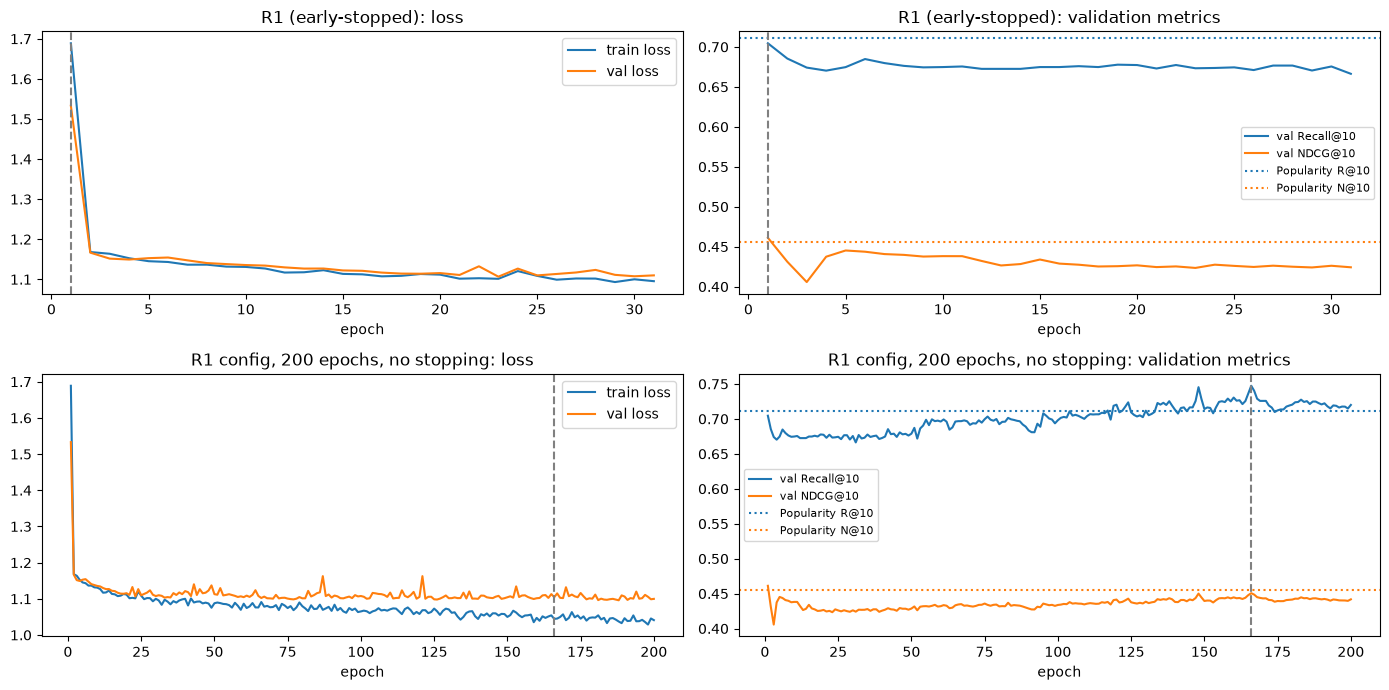

epoch of max val NDCG@10: 1 | max NDCG@10 0.4612 | max R@10 0.7474 | final train/val loss 1.0411 1.0998


In [56]:
def plot_curves(run, title, ax=None):
    h = run['hist']
    if ax is None: fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
    ax[0].plot(h.epoch, h.train_loss, label='train loss'); ax[0].plot(h.epoch, h.val_loss, label='val loss')
    ax[0].axvline(run['best_epoch'], ls='--', c='grey'); ax[0].set_title(f'{title}: loss'); ax[0].legend(); ax[0].set_xlabel('epoch')
    ax[1].plot(h.epoch, h.val_recall10, label='val Recall@10'); ax[1].plot(h.epoch, h.val_ndcg10, label='val NDCG@10')
    ax[1].axhline(RESULTS_VAL['Popularity']['Recall@10'], ls=':', c='C0', label='Popularity R@10')
    ax[1].axhline(RESULTS_VAL['Popularity']['NDCG@10'], ls=':', c='C1', label='Popularity N@10')
    ax[1].axvline(run['best_epoch'], ls='--', c='grey'); ax[1].set_title(f'{title}: validation metrics'); ax[1].legend(fontsize=8); ax[1].set_xlabel('epoch')

# longer diagnostic run of the same config without early stopping, to see the full trajectory
r1_long = train_gnn(BASE_GCN, max_epochs=200, patience=10**9)
fig, ax = plt.subplots(2, 2, figsize=(14, 7))
plot_curves(r1, 'R1 (early-stopped)', ax[0]); plot_curves(r1_long, 'R1 config, 200 epochs, no stopping', ax[1])
plt.tight_layout(); plt.show()
h = r1_long['hist']; print('epoch of max val NDCG@10:', int(h.loc[h.val_ndcg10.idxmax(), 'epoch']), '| max NDCG@10', round(h.val_ndcg10.max(), 4),
      '| max R@10', round(h.val_recall10.max(), 4), '| final train/val loss', round(h.train_loss.iloc[-1], 4), round(h.val_loss.iloc[-1], 4))

**Insight (R1 learning curves).** *Expected* a standard curve where validation improves and then overfits. *Observed* something different:
- At **epoch 1** (10 Adam steps from initialisation) the model already matches popularity on NDCG@10 (0.461). An almost untrained GCN produces popularity-like scores: high-degree items aggregate many customer messages, which acts as a degree prior.
- It then **drops** (NDCG ≈ 0.41–0.43) while the item embeddings move away from that prior, and slowly recovers over 150+ epochs. Recall@10 peaks at 0.747 (epoch ~165), but NDCG@10 never re-exceeds ~0.445.
- **Train loss keeps falling while val loss is flat (~1.10) from about epoch 25**, so the extra fitting is not transferring. This is consistent with Phase 2: nothing generalisable beyond popularity.
- Val Recall@10 is noisy (445 customers, so SE ≈ ±0.02), and picking the max over many epochs is optimistic.

**Change to the protocol (applied to every GNN run from here on):** patience 30 → **50** and max epochs **300**. The model needs about 150 epochs to recover, so patience 30 locks in the near-initial state. The stopping criterion stays val Recall@10 (NDCG tie-break) as specified. *Next:* re-run R1 under this protocol, then R2–R7.

In [57]:
PATIENCE, MAX_EP = 50, 300
EXP_LOG = []          # restart the log under the final protocol
def run_cfg(cfg, rnd, name, change, seed=SEED):
    r = train_gnn(cfg, seed=seed, max_epochs=MAX_EP, patience=PATIENCE)
    log_run(rnd, name, change, r)
    v = r['val']; print(f"{rnd:4s} {change:38s} R@10 {v['Recall@10']:.4f}  N@10 {v['NDCG@10']:.4f}  PR-AUC {v['PR-AUC']:.4f}  best_ep {r['best_epoch']:3d}  {r['runtime']:.0f}s")
    return r

r1 = run_cfg(BASE_GCN, 'R1', 'GCN', 'baseline (2L, d64, drop .3, lr 1e-3)')
r2 = run_cfg({**BASE_GCN, 'use_ew': True}, 'R2', 'GCN', 'edge_weight = log(1+#orders)')

R1   baseline (2L, d64, drop .3, lr 1e-3)   R@10 0.7045  N@10 0.4612  PR-AUC 0.1552  best_ep   1  3s
R2   edge_weight = log(1+#orders)           R@10 0.7485  N@10 0.4506  PR-AUC 0.1840  best_ep 292  20s


**Insight (R1 vs R2, first try).** R1 *again* stopped at epoch 1. The near-initial state's Recall@10 (0.7045) beats every epoch in the next 50, so patience 50 is still not enough to pass the dip. R2 (edge weights) avoided the trap and trained to epoch 292: Recall@10 0.749, PR-AUC 0.184, but NDCG@10 0.451. **This comparison is confounded by the stopping artefact**, not by the edge weights, so I won't draw a conclusion from it.

**Fix:** a **warm-up of 50 epochs** before checkpoint selection starts. Selection still uses val Recall@10 (NDCG tie-break) with patience 50 after warm-up. This is standard practice and removes the "untrained model wins" artefact without changing the criterion. The epoch-1 popularity-like state stays represented by the Popularity baseline itself. *Next:* redefine `train_gnn` with `min_epochs` and re-run R1 and R2.

In [58]:
MIN_EP = 50
def train_gnn(cfg, seed=SEED, max_epochs=300, patience=50, min_epochs=MIN_EP, verbose=False, train_split='train'):
    set_seed(seed); rng = np.random.default_rng(seed)
    model = BipartiteGNN(**{k: v for k, v in cfg.items() if k not in ('lr', 'wd')}).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    train_snaps, val_snaps = SPLIT_SNAPS[train_split], SPLIT_SNAPS['val']
    yv = stack(val_snaps, 'Y'); hist = []; best = (-1, -1); best_state, best_ep, wait, best_m = None, 0, 0, None
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        model.train(); losses = []
        for k in rng.permutation(len(train_snaps)):
            opt.zero_grad(); loss = snapshot_loss(model, train_snaps[k], rng); loss.backward(); opt.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            vrng = np.random.default_rng(123); vloss = np.mean([snapshot_loss(model, s, vrng).item() for s in val_snaps])
        m = evaluate(gnn_scores(model, val_snaps), yv)
        hist.append({'epoch': ep, 'train_loss': np.mean(losses), 'val_loss': vloss, 'val_recall10': m['Recall@10'],
                     'val_ndcg10': m['NDCG@10'], 'val_prauc': m['PR-AUC']})
        if ep < min_epochs: continue                      # warm-up: no checkpoint selection yet
        key = (round(m['Recall@10'], 6), m['NDCG@10'])
        if key > best:
            best, best_ep, wait, best_m = key, ep, 0, m; best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    return dict(model=model, hist=pd.DataFrame(hist), best_epoch=best_ep, val=best_m, runtime=time.time() - t0,
                params=n_params(model), cfg=cfg, seed=seed)

EXP_LOG = []
r1 = run_cfg(BASE_GCN, 'R1', 'GCN', 'baseline (2L, d64, drop .3, lr 1e-3)')
r2 = run_cfg({**BASE_GCN, 'use_ew': True}, 'R2', 'GCN', 'edge_weight = log(1+#orders)')

R1   baseline (2L, d64, drop .3, lr 1e-3)   R@10 0.7474  N@10 0.4506  PR-AUC 0.1848  best_ep 166  14s
R2   edge_weight = log(1+#orders)           R@10 0.7485  N@10 0.4506  PR-AUC 0.1840  best_ep 292  20s


**Insight (R1, R2 with warm-up).** With the artefact removed, R1 trains properly (best epoch 166): Recall@10 **0.747**, NDCG@10 0.451, PR-AUC 0.185. R2's edge weights give **no change** (0.749 / 0.451 / 0.184). That fits Phase 2: repeat counts carry no extra signal (29% of edges repeat, and persistence OR ≈ 1). Compared with Popularity (0.711 / 0.456 / 0.186): **+3.6 points of Recall@10, but slightly lower NDCG@10 and PR-AUC.** The GCN gets more of the right sub-categories into the top 10 but ranks the very top slightly worse.

**Tuning rule (fixed in advance):** with 445 validation customers, Recall@10 has SE ≈ 0.02. A change is **adopted only if val Recall@10 improves by ≥ 0.01**. Otherwise the simpler/default value is kept. Decision for R2: **keep no edge weights** (+0.001 < 0.01).

**R3: number of layers ∈ {1, 2, 3, 4}**, everything else as R1. This also gives the performance-vs-depth curve for the over-smoothing analysis.

In [59]:
EXP_LOG[0]['conclusion'] = 'reference'; EXP_LOG[1]['conclusion'] = 'no gain (+0.001) -> keep unweighted'
GCN_CUR = dict(BASE_GCN)
SENS = {}                                   # hyper-parameter sensitivity, for the plots
def tune_round(rnd, param, values, cur, name='GCN'):
    runs = {}
    for v in values:
        cfg = {**cur, param: v}
        runs[v] = r1 if (name == 'GCN' and cfg == BASE_GCN) else run_cfg(cfg, rnd, name, f'{param} = {v}')
        if name == 'GCN' and cfg == BASE_GCN: print(f'{rnd:4s} {param} = {v} (current config, = R1)  R@10 {r1["val"]["Recall@10"]:.4f}')
    SENS[(name, param)] = {v: r['val'] for v, r in runs.items()}
    cur_v = cur[param]; best_v = max(runs, key=lambda v: runs[v]['val']['Recall@10'])
    gain = runs[best_v]['val']['Recall@10'] - runs[cur_v]['val']['Recall@10']
    chosen = best_v if gain >= 0.01 else cur_v
    print(f'-> best {param} = {best_v} (gain {gain:+.4f}); adopted: {chosen}')
    return chosen, runs

best_layers, R3 = tune_round('R3', 'layers', [1, 2, 3, 4], GCN_CUR)
GCN_CUR['layers'] = best_layers

R3   layers = 1                             R@10 0.7205  N@10 0.4529  PR-AUC 0.1798  best_ep 113  6s
R3   layers = 2 (current config, = R1)  R@10 0.7474
R3   layers = 3                             R@10 0.7088  N@10 0.4386  PR-AUC 0.1804  best_ep  56  10s
R3   layers = 4                             R@10 0.7250  N@10 0.4436  PR-AUC 0.1749  best_ep 141  23s
-> best layers = 2 (gain +0.0000); adopted: 2


**Insight (R3, depth).** Recall@10: 1 layer 0.721, **2 layers 0.747**, 3 layers 0.709, 4 layers 0.725. NDCG@10 is flat (0.439–0.453). Two layers is best, but the spread (0.04) is only about 2 SE and is not monotone, so depth hardly matters. That is expected when the only exploitable signal is popularity: one hop (customer → sub-category) already reaches every relevant item. In a bipartite graph, 2 hops is the first depth at which a customer's representation mixes in other customers' tastes (u → c → u'). The over-smoothing analysis later checks what happens to the embeddings themselves. **Adopted: 2 layers.**

**R4: hidden dimension ∈ {32, 64, 128}.**

In [60]:
EXP_LOG[-1]['conclusion'] = 'no gain >= .01 -> keep 2 layers'
best_hidden, R4 = tune_round('R4', 'hidden', [32, 64, 128], GCN_CUR)
GCN_CUR['hidden'] = best_hidden

R4   hidden = 32                            R@10 0.7443  N@10 0.4460  PR-AUC 0.1795  best_ep 116  9s
R4   hidden = 64 (current config, = R1)  R@10 0.7474
R4   hidden = 128                           R@10 0.7547  N@10 0.4565  PR-AUC 0.1843  best_ep 178  21s
-> best hidden = 128 (gain +0.0073); adopted: 64


**Insight (R4, width).** d = 32: 0.744 / 0.446; d = 64: 0.747 / 0.451; d = 128: **0.755 / 0.457** (Recall@10 / NDCG@10). There is a small monotone trend with width, but +0.007 is below the pre-set 0.01 threshold, so **d = 64 is kept**. With 17 items and popularity as the main signal, extra capacity is not needed (d = 128 has about 4× the parameters for a within-noise gain).

**R5: dropout ∈ {0, 0.1, 0.3, 0.5}.**

In [61]:
EXP_LOG[-1]['conclusion'] = '+0.007 < .01 -> keep d=64'
best_drop, R5 = tune_round('R5', 'dropout', [0.0, 0.1, 0.3, 0.5], GCN_CUR)
GCN_CUR['dropout'] = best_drop

R5   dropout = 0.0                          R@10 0.7634  N@10 0.4537  PR-AUC 0.1848  best_ep  90  9s
R5   dropout = 0.1                          R@10 0.7629  N@10 0.4556  PR-AUC 0.1848  best_ep 117  11s
R5   dropout = 0.3 (current config, = R1)  R@10 0.7474
R5   dropout = 0.5                          R@10 0.7118  N@10 0.4404  PR-AUC 0.1788  best_ep  81  8s
-> best dropout = 0.0 (gain +0.0160); adopted: 0.0


**Insight (R5, dropout).** Recall@10 falls steadily with more dropout: 0.0 → **0.763**, 0.1 → 0.763, 0.3 → 0.747, 0.5 → 0.712. NDCG@10 peaks at 0.1 (0.456). Dropout 0 clears the +0.01 rule (+0.016), so it is **adopted (dropout = 0.0)**. Dropout 0.1 is statistically the same. *Interpretation:* the model is small (10k parameters) and the signal is simple, so dropout mostly adds noise. Overfitting, visible as the train/val loss gap in R1, is better handled by weight decay, which is next.

**R6: weight decay ∈ {1e-6, 1e-5, 1e-4, 1e-3}** (current: 0).

In [62]:
EXP_LOG[-1]['conclusion'] = '+0.016 -> adopt dropout 0'
# current config (wd = 0) is the dropout-0 run from R5; include it as the reference value
r_cur = R5[0.0]
R6 = {0.0: r_cur}
for wd in [1e-6, 1e-5, 1e-4, 1e-3]:
    R6[wd] = run_cfg({**GCN_CUR, 'wd': wd}, 'R6', 'GCN', f'weight decay = {wd:g}')
SENS[('GCN', 'wd')] = {k: v['val'] for k, v in R6.items()}
best_wd = max(R6, key=lambda k: R6[k]['val']['Recall@10']); gain = R6[best_wd]['val']['Recall@10'] - R6[0.0]['val']['Recall@10']
GCN_CUR['wd'] = best_wd if gain >= 0.01 else 0.0
print(f'-> best wd = {best_wd:g} (gain {gain:+.4f}); adopted: {GCN_CUR["wd"]:g}')

R6   weight decay = 1e-06                   R@10 0.7621  N@10 0.4536  PR-AUC 0.1852  best_ep  90  8s
R6   weight decay = 1e-05                   R@10 0.7629  N@10 0.4568  PR-AUC 0.1827  best_ep 133  11s
R6   weight decay = 0.0001                  R@10 0.7646  N@10 0.4552  PR-AUC 0.1848  best_ep  90  9s
R6   weight decay = 0.001                   R@10 0.7174  N@10 0.4378  PR-AUC 0.1776  best_ep  89  9s
-> best wd = 0.0001 (gain +0.0011); adopted: 0


**Insight (R6, weight decay).** wd ≤ 1e-4 is indistinguishable from none (Recall@10 0.762–0.765). wd = 1e-3 over-regularises (0.717), shrinking embeddings back toward the popularity-like state. Best gain is +0.001, so **wd = 0 is kept**.

**R7: learning rate ∈ {3e-4, 1e-3, 3e-3}.** Note: lr interacts with the 50-epoch warm-up. 3e-4 may still be in the early dip when checkpointing starts.

In [63]:
EXP_LOG[-1]['conclusion'] = 'wd<=1e-4 no gain, 1e-3 hurts -> keep 0'
R7 = {1e-3: r_cur}
for lr in [3e-4, 3e-3]:
    R7[lr] = run_cfg({**GCN_CUR, 'lr': lr}, 'R7', 'GCN', f'learning rate = {lr:g}')
SENS[('GCN', 'lr')] = {k: v['val'] for k, v in R7.items()}
best_lr = max(R7, key=lambda k: R7[k]['val']['Recall@10']); gain = R7[best_lr]['val']['Recall@10'] - R7[1e-3]['val']['Recall@10']
GCN_CUR['lr'] = best_lr if gain >= 0.01 else 1e-3
EXP_LOG[-1]['conclusion'] = f'adopted lr {GCN_CUR["lr"]:g}'
print(f'-> best lr = {best_lr:g} (gain {gain:+.4f}); adopted: {GCN_CUR["lr"]:g}')
print('\nFINAL GCN CONFIG:', GCN_CUR)
BEST_GCN_RUN = R7[GCN_CUR['lr']] if GCN_CUR['lr'] in R7 else r_cur
print('val:', {k: round(BEST_GCN_RUN['val'][k], 4) for k in ['Recall@10','NDCG@10','PR-AUC','Recall@5','NDCG@5']}, '| params', BEST_GCN_RUN['params'])

R7   learning rate = 0.0003                 R@10 0.7687  N@10 0.4579  PR-AUC 0.1829  best_ep 188  15s
R7   learning rate = 0.003                  R@10 0.7565  N@10 0.4597  PR-AUC 0.1864  best_ep  65  8s
-> best lr = 0.0003 (gain +0.0053); adopted: 0.001

FINAL GCN CONFIG: {'conv': 'gcn', 'hidden': 64, 'layers': 2, 'dropout': 0.0, 'use_ew': False, 'lr': 0.001, 'wd': 0.0}
val: {'Recall@10': np.float64(0.7634), 'NDCG@10': np.float64(0.4537), 'PR-AUC': 0.1848, 'Recall@5': np.float64(0.466), 'NDCG@5': np.float64(0.3456)} | params 10368


**Insight (R7, learning rate).** 3e-4: 0.769 / 0.458; 1e-3: 0.763 / 0.454; 3e-3: 0.757 / 0.460. All within ±0.006 Recall@10, so **lr = 1e-3 is kept**. The larger lr converges in a third of the epochs (best epoch 65 vs 188) to the same place.

**Final GCN (val):** 2 layers, d = 64, dropout 0, no edge weights, lr 1e-3, wd 0. Recall@10 **0.763**, NDCG@10 0.454, PR-AUC 0.185, 10.4k parameters.

**Tuning summary:** of the six rounds, only dropout 0.3 → 0 cleared the 0.01 threshold (+0.016). Everything else moved Recall@10 by < 0.01. Total gain over R1 is +0.016 Recall@10, +0.003 NDCG@10, PR-AUC unchanged. *Next:* learning curves of the final GCN.

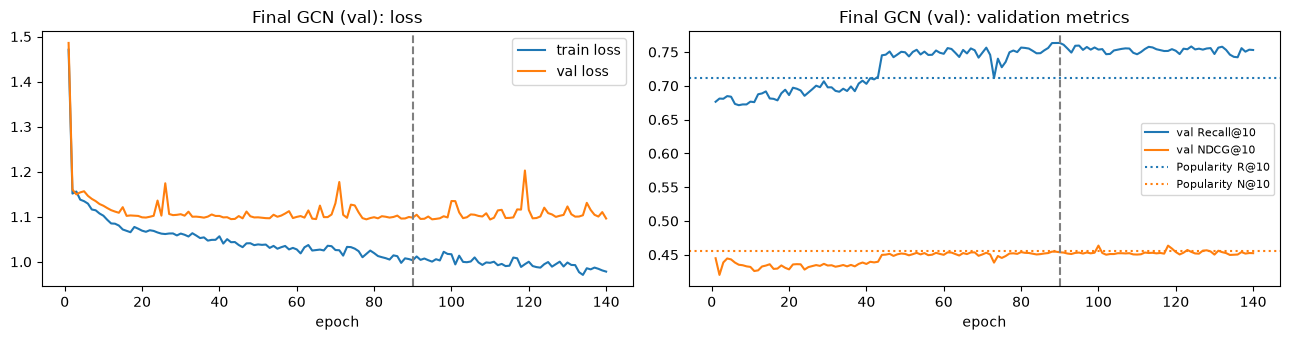

In [64]:
plot_curves(BEST_GCN_RUN, 'Final GCN (val)'); plt.tight_layout(); plt.show()

**Insight (final GCN curves).** Train loss keeps decreasing while val loss flattens at ~1.07 from about epoch 30, with occasional spikes (single noisy snapshots). Val Recall@10 rises in a step around epoch 40 and plateaus at ~0.75–0.77, *above* popularity (0.711). Val NDCG@10 sits on the popularity line (~0.45). So the GCN reorders the 4th–10th positions slightly better than popularity, but not the top ones.

## Phase 6 — GAT (identical pipeline, only the encoder changes)

Same features, split, dot-product decoder, loss, 1:4 negatives, warm-up + early stopping, and the same 0.01 adoption rule. **Starting config:** 2 layers, **4 heads** (concat in the hidden layer, mean in the last), total hidden 64, attention dropout 0.1, and GCN's tuned dropout 0 / lr 1e-3 / wd 0. GAT ignores edge weights (GCN showed they don't help).

**Rounds:** G1 baseline; G2 heads {1, 2, 4, 8}; G3 layers {1, 2, 3}; G4 attention dropout {0, 0.1, 0.3}; G5 dropout {0, 0.1, 0.3, 0.5}; G6 weight decay {1e-6 … 1e-3}.

In [65]:
RUN_CACHE = {}
def cached_run(cfg, rnd, name, change):
    key = tuple(sorted(cfg.items()))
    if key not in RUN_CACHE: RUN_CACHE[key] = run_cfg(cfg, rnd, name, change)
    else: print(f'{rnd:4s} {change:38s} (same as current config) R@10 {RUN_CACHE[key]["val"]["Recall@10"]:.4f}')
    return RUN_CACHE[key]

def tune_gat(rnd, param, values, cur):
    runs = {v: cached_run({**cur, param: v}, rnd, 'GAT', f'{param} = {v}') for v in values}
    SENS[('GAT', param)] = {v: r['val'] for v, r in runs.items()}
    ref = cached_run(cur, rnd, 'GAT', f'{param} = {cur[param]}')
    best_v = max(runs, key=lambda v: runs[v]['val']['Recall@10']); gain = runs[best_v]['val']['Recall@10'] - ref['val']['Recall@10']
    chosen = best_v if gain >= 0.01 else cur[param]
    EXP_LOG[-1]['conclusion'] = f'best {param}={best_v} gain {gain:+.3f} -> adopt {chosen}'
    print(f'-> best {param} = {best_v} (gain {gain:+.4f}); adopted: {chosen}')
    return chosen

GAT_CUR = dict(conv='gat', hidden=64, layers=2, heads=4, att_dropout=0.1, dropout=0.0, use_ew=False, lr=1e-3, wd=0.0)
g1 = cached_run(GAT_CUR, 'G1', 'GAT', 'baseline (2L, 4 heads, d64, att-drop .1)')
EXP_LOG[-1]['conclusion'] = 'GAT reference'
GAT_CUR['heads'] = tune_gat('G2', 'heads', [1, 2, 4, 8], GAT_CUR)

G1   baseline (2L, 4 heads, d64, att-drop .1) R@10 0.7778  N@10 0.4749  PR-AUC 0.1880  best_ep  67  14s
G2   heads = 1                              R@10 0.7628  N@10 0.4630  PR-AUC 0.1786  best_ep  51  9s
G2   heads = 2                              R@10 0.7691  N@10 0.4782  PR-AUC 0.1842  best_ep  97  15s
G2   heads = 4                              (same as current config) R@10 0.7778
G2   heads = 8                              R@10 0.7532  N@10 0.4640  PR-AUC 0.1779  best_ep  69  19s
G2   heads = 4                              (same as current config) R@10 0.7778
-> best heads = 4 (gain +0.0000); adopted: 4


**Insight (G1, G2).** The GAT baseline is the **best validation model so far**: Recall@10 **0.778**, NDCG@10 **0.475**, PR-AUC 0.188. That is +0.015 / +0.021 over the final GCN, and the first model to clearly exceed popularity on NDCG@10 (+0.019). *Caution:* one seed on 445 customers, so this needs the 5-seed test check before it means anything. Heads: 1 → 0.763, 2 → 0.769, **4 → 0.778**, 8 → 0.753. Four is best but the spread is within ~1 SE, so **4 heads are kept**. With 8 heads the per-head width is only 8 dims, which may be too narrow.

**G3: layers ∈ {1, 2, 3}** and **G4: attention dropout ∈ {0, 0.1, 0.3}**.

In [66]:
GAT_CUR['layers'] = tune_gat('G3', 'layers', [1, 2, 3], GAT_CUR)
GAT_CUR['att_dropout'] = tune_gat('G4', 'att_dropout', [0.0, 0.1, 0.3], GAT_CUR)

G3   layers = 1                             R@10 0.7404  N@10 0.4549  PR-AUC 0.1827  best_ep  57  11s
G3   layers = 2                             (same as current config) R@10 0.7778
G3   layers = 3                             R@10 0.7541  N@10 0.4533  PR-AUC 0.1799  best_ep 262  64s
G3   layers = 2                             (same as current config) R@10 0.7778
-> best layers = 2 (gain +0.0000); adopted: 2
G4   att_dropout = 0.0                      R@10 0.7778  N@10 0.4631  PR-AUC 0.1824  best_ep  84  21s
G4   att_dropout = 0.1                      (same as current config) R@10 0.7778
G4   att_dropout = 0.3                      R@10 0.7778  N@10 0.4611  PR-AUC 0.1787  best_ep  61  18s
G4   att_dropout = 0.1                      (same as current config) R@10 0.7778
-> best att_dropout = 0.1 (gain +0.0000); adopted: 0.1


**Insight (G3, G4).** Depth: 1 layer 0.740, **2 layers 0.778**, 3 layers 0.754. The same inverted-U as GCN: 2 layers is the sweet spot, and the 3-layer GAT needed 262 epochs. Attention dropout: Recall@10 is *identical* (0.7778) for 0, 0.1 and 0.3, and NDCG@10 is highest at 0.1 (0.475 vs 0.463 / 0.461). Identical Recall@10 values show how **coarse Recall@10 is with 17 items**: many configurations put the same customers' items in the top 10. **Kept: 2 layers, attention dropout 0.1.**

**G5: dropout ∈ {0, 0.1, 0.3, 0.5}** and **G6: weight decay ∈ {1e-6, 1e-5, 1e-4, 1e-3}**.

In [67]:
GAT_CUR['dropout'] = tune_gat('G5', 'dropout', [0.0, 0.1, 0.3, 0.5], GAT_CUR)
GAT_CUR['wd'] = tune_gat('G6', 'wd', [0.0, 1e-6, 1e-5, 1e-4, 1e-3], GAT_CUR)
BEST_GAT_RUN = RUN_CACHE[tuple(sorted(GAT_CUR.items()))]
print('\nFINAL GAT CONFIG:', GAT_CUR)
print('val:', {k: round(BEST_GAT_RUN['val'][k], 4) for k in ['Recall@10','NDCG@10','PR-AUC','Recall@5','NDCG@5']}, '| params', BEST_GAT_RUN['params'])

G5   dropout = 0.0                          (same as current config) R@10 0.7778
G5   dropout = 0.1                          R@10 0.7829  N@10 0.4627  PR-AUC 0.1801  best_ep  61  18s
G5   dropout = 0.3                          R@10 0.7803  N@10 0.4767  PR-AUC 0.1868  best_ep  96  24s
G5   dropout = 0.5                          R@10 0.7614  N@10 0.4567  PR-AUC 0.1795  best_ep 111  28s
G5   dropout = 0.0                          (same as current config) R@10 0.7778
-> best dropout = 0.1 (gain +0.0051); adopted: 0.0
G6   wd = 0.0                               (same as current config) R@10 0.7778
G6   wd = 1e-06                             R@10 0.7779  N@10 0.4559  PR-AUC 0.1832  best_ep  69  17s
G6   wd = 1e-05                             R@10 0.7794  N@10 0.4738  PR-AUC 0.1879  best_ep  53  15s
G6   wd = 0.0001                            R@10 0.7803  N@10 0.4760  PR-AUC 0.1839  best_ep  66  16s
G6   wd = 0.001                             R@10 0.7875  N@10 0.4627  PR-AUC 0.1804  best_ep  

**Insight (G5, G6).** Dropout: 0 → 0.778, 0.1 → 0.783, 0.3 → 0.780 (NDCG 0.477), 0.5 → 0.761. Weight decay: 1e-6 → 0.778, 1e-5 → 0.779, 1e-4 → 0.780, 1e-3 → 0.788 (but NDCG drops to 0.463). No change reaches the +0.01 rule (largest +0.0097), so **the GAT baseline config is final**: 2 layers, 4 heads, d = 64, attention dropout 0.1, dropout 0, wd 0. Val Recall@10 **0.778**, NDCG@10 **0.475**, PR-AUC 0.188, 23.3k parameters.

*Note on runtimes:* two G6 runs show 692 s and 964 s instead of ~20 s. The host machine stalled (the browser was also unresponsive then), so **tuning-time runtimes are not reliable**. Runtime comparisons use only the final 5-seed runs.

**Tuning summary (GAT):** no round improved on the starting config by ≥ 0.01. GAT's advantage over GCN on validation (+0.015 Recall@10, +0.021 NDCG@10) is there *from the starting config*, so it comes from the attention mechanism, not from tuning. *Next:* GAT learning curves, then Phase 7.

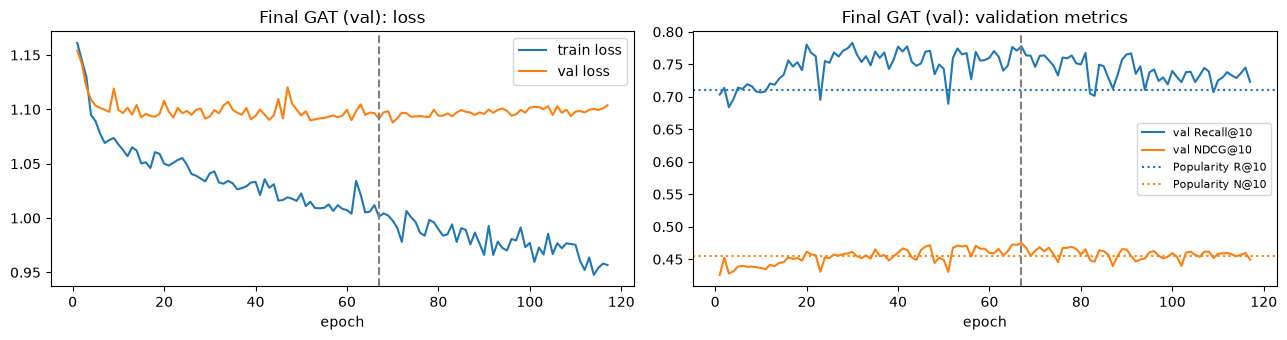

   round model                                    change  Val Recall@10  Val NDCG@10  Val PR-AUC  best_epoch                                     conclusion
0     R1   GCN      baseline (2L, d64, drop .3, lr 1e-3)         0.7474       0.4506      0.1848         166                                      reference
1     R2   GCN              edge_weight = log(1+#orders)         0.7485       0.4506      0.1840         292            no gain (+0.001) -> keep unweighted
2     R3   GCN                                layers = 1         0.7205       0.4529      0.1798         113                                               
3     R3   GCN                                layers = 3         0.7088       0.4386      0.1804          56                                               
4     R3   GCN                                layers = 4         0.7250       0.4436      0.1749         141                no gain >= .01 -> keep 2 layers
5     R4   GCN                               hidden = 32        

In [68]:
plot_curves(BEST_GAT_RUN, 'Final GAT (val)'); plt.tight_layout(); plt.show()
print(pd.DataFrame(EXP_LOG)[['round','model','change','Val Recall@10','Val NDCG@10','Val PR-AUC','best_epoch','conclusion']].round(4).to_string())

**Insight (GAT curves).** The GAT overfits faster and harder than the GCN. Train loss falls from 1.15 to 0.95, while **val loss bottoms out around epoch 60 and then rises**. Val NDCG@10 stays just above the popularity line throughout, and the checkpoint (epoch 67) sits at the val-loss minimum. Twice the parameters (23k vs 10k) and per-edge attention give it more room to memorise snapshot-specific purchases. That is why weight decay 1e-3 and dropout 0.1–0.3 were near the adoption threshold.

The table above is the full tuning log. Next I copy it into the **Experiment Log** cell near the top of this section.

In [69]:
def exp_log_markdown(extra_rows=()):
    lines = ['## Experiment Log', '',
             '*Validation set (targets 2013Q4–2014Q1, 445 customers). Adoption rule: change kept only if val Recall@10 improves by ≥ 0.01. Reference: Popularity R@10 0.711 / NDCG@10 0.456 / PR-AUC 0.186.*', '',
             '| Round | Model | Change | Val Recall@10 | Val NDCG@10 | Val PR-AUC | Conclusion |', '|---|---|---|---|---|---|---|']
    for r in EXP_LOG:
        lines.append(f"| {r['round']} | {r['model']} | {r['change']} | {r['Val Recall@10']:.4f} | {r['Val NDCG@10']:.4f} | {r['Val PR-AUC']:.4f} | {r['conclusion']} |")
    lines += list(extra_rows)
    return '\n'.join(lines)
EXP_MD = exp_log_markdown()
print(EXP_MD)

## Experiment Log

*Validation set (targets 2013Q4–2014Q1, 445 customers). Adoption rule: change kept only if val Recall@10 improves by ≥ 0.01. Reference: Popularity R@10 0.711 / NDCG@10 0.456 / PR-AUC 0.186.*

| Round | Model | Change | Val Recall@10 | Val NDCG@10 | Val PR-AUC | Conclusion |
|---|---|---|---|---|---|---|
| R1 | GCN | baseline (2L, d64, drop .3, lr 1e-3) | 0.7474 | 0.4506 | 0.1848 | reference |
| R2 | GCN | edge_weight = log(1+#orders) | 0.7485 | 0.4506 | 0.1840 | no gain (+0.001) -> keep unweighted |
| R3 | GCN | layers = 1 | 0.7205 | 0.4529 | 0.1798 |  |
| R3 | GCN | layers = 3 | 0.7088 | 0.4386 | 0.1804 |  |
| R3 | GCN | layers = 4 | 0.7250 | 0.4436 | 0.1749 | no gain >= .01 -> keep 2 layers |
| R4 | GCN | hidden = 32 | 0.7443 | 0.4460 | 0.1795 |  |
| R4 | GCN | hidden = 128 | 0.7547 | 0.4565 | 0.1843 | +0.007 < .01 -> keep d=64 |
| R5 | GCN | dropout = 0.0 | 0.7634 | 0.4537 | 0.1848 |  |
| R5 | GCN | dropout = 0.1 | 0.7629 | 0.4556 | 0.1848 |  |
| R5 | GCN | dropou

## Phase 7 — Final evaluation on the TEST set (5 seeds)

**What:** for seeds 0–4, retrain the final GCN, the final GAT, LogReg and MLP with exactly the tuned configs (training snapshots only, validation for early stopping, same warm-up/patience). Evaluate each **once on the test targets** (2014Q2–Q4, 872 customer-quarters). The heuristics are deterministic, so their std is 0. I record parameter counts and wall-clock training time, and keep every model's test score matrix for the analyses that follow.

**Decision rule:** model A is called better than B only if mean(A) − mean(B) > max(std_A, std_B) on the metric in question.

In [70]:
SEEDS = [0, 1, 2, 3, 4]
Y_TEST = stack(SPLIT_SNAPS['test'], 'Y')
FINAL = {m: [] for m in ['Popularity','Repeat-last-period','Repeat-frequent','LogReg','MLP','GCN','GAT']}
TEST_SCORES = {m: [] for m in FINAL}
FINAL_MODELS = {'GCN': [], 'GAT': []}
RUNTIME = {m: [] for m in FINAL}; PARAMS = {}

for name, fn in HEURISTICS.items():
    t0 = time.time(); S = np.vstack([fn(s) for s in SPLIT_SNAPS['test']]); RUNTIME[name].append(time.time() - t0)
    TEST_SCORES[name].append(S); FINAL[name].append(evaluate(S, Y_TEST)); PARAMS[name] = 0 if name != 'Popularity' else N_ITEMS

for seed in SEEDS:
    for name, fitter in [('LogReg', fit_lr), ('MLP', fit_mlp)]:
        t0 = time.time(); m = fitter(seed); RUNTIME[name].append(time.time() - t0)
        S = np.vstack([sk_score(m)(s) for s in SPLIT_SNAPS['test']]); TEST_SCORES[name].append(S); FINAL[name].append(evaluate(S, Y_TEST))
        PARAMS[name] = m.coef_.size + 1 if name == 'LogReg' else sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
    for name, cfg in [('GCN', GCN_CUR), ('GAT', GAT_CUR)]:
        r = train_gnn(cfg, seed=seed, max_epochs=MAX_EP, patience=PATIENCE)
        RUNTIME[name].append(r['runtime']); PARAMS[name] = r['params']; FINAL_MODELS[name].append(r)
        S = gnn_scores(r['model'], SPLIT_SNAPS['test']); TEST_SCORES[name].append(S); FINAL[name].append(evaluate(S, Y_TEST))
    print(f'seed {seed} done | GCN R@10 {FINAL["GCN"][-1]["Recall@10"]:.4f} GAT R@10 {FINAL["GAT"][-1]["Recall@10"]:.4f}', flush=True)
print('all seeds finished')

seed 0 done | GCN R@10 0.7147 GAT R@10 0.7162
seed 1 done | GCN R@10 0.7074 GAT R@10 0.7211
seed 2 done | GCN R@10 0.7182 GAT R@10 0.7110
seed 3 done | GCN R@10 0.7118 GAT R@10 0.6901
seed 4 done | GCN R@10 0.7119 GAT R@10 0.7103
all seeds finished


In [71]:
METRICS = ['Recall@5','NDCG@5','Precision@5','HitRate@5','Recall@10','NDCG@10','Precision@10','HitRate@10','Recall@20','NDCG@20','PR-AUC','ROC-AUC','micro-F1@2']
rows = {}
for m, res in FINAL.items():
    d = pd.DataFrame(res)[METRICS]
    rows[m] = {**{f'{k}': f'{d[k].mean():.4f} ± {d[k].std(ddof=0):.4f}' for k in METRICS},
               'params': PARAMS[m], 'train time (s)': f'{np.mean(RUNTIME[m]):.1f}'}
FINAL_TABLE = pd.DataFrame(rows).T
MEAN = {m: pd.DataFrame(r)[METRICS].mean() for m, r in FINAL.items()}
STD = {m: pd.DataFrame(r)[METRICS].std(ddof=0) for m, r in FINAL.items()}
display(FINAL_TABLE[['Recall@5','NDCG@5','Recall@10','NDCG@10','PR-AUC','ROC-AUC','micro-F1@2','params','train time (s)']])

def better(a, b, k):
    gap = MEAN[a][k] - MEAN[b][k]; thr = max(STD[a][k], STD[b][k])
    return gap, thr, ('BETTER' if gap > thr else 'WORSE' if -gap > thr else 'no difference')
for a, b in [('GCN','Popularity'), ('GAT','Popularity'), ('GAT','GCN'), ('GCN','LogReg'), ('GAT','MLP'), ('Popularity','Repeat-last-period')]:
    print(f'{a:10s} vs {b:18s}: ' + ' | '.join(f'{k} {better(a,b,k)[0]:+.4f} (thr {better(a,b,k)[1]:.4f}) {better(a,b,k)[2]}' for k in ['Recall@10','NDCG@10','PR-AUC']))

,Recall@5,NDCG@5,Recall@10,NDCG@10,PR-AUC,ROC-AUC,micro-F1@2,params,train time (s)
Popularity,0.4848 ± 0.0000,0.3847 ± 0.0000,0.7246 ± 0.0000,0.4748 ± 0.0000,0.2061 ± 0.0000,0.6370 ± 0.0000,0.2575 ± 0.0000,17,0.0
Repeat-last-period,0.4196 ± 0.0000,0.3203 ± 0.0000,0.7079 ± 0.0000,0.4309 ± 0.0000,0.1773 ± 0.0000,0.6042 ± 0.0000,0.2067 ± 0.0000,0,0.0
Repeat-frequent,0.4239 ± 0.0000,0.3264 ± 0.0000,0.7077 ± 0.0000,0.4356 ± 0.0000,0.1858 ± 0.0000,0.6075 ± 0.0000,0.2138 ± 0.0000,0,0.0
LogReg,0.4808 ± 0.0000,0.3830 ± 0.0000,0.7225 ± 0.0000,0.4730 ± 0.0000,0.2083 ± 0.0000,0.6396 ± 0.0000,0.2564 ± 0.0000,38,0.2
MLP,0.4676 ± 0.0192,0.3737 ± 0.0170,0.7131 ± 0.0100,0.4668 ± 0.0115,0.1878 ± 0.0065,0.6041 ± 0.0096,0.2530 ± 0.0122,2497,1.5
GCN,0.4755 ± 0.0104,0.3774 ± 0.0051,0.7128 ± 0.0036,0.4668 ± 0.0016,0.2002 ± 0.0064,0.6207 ± 0.0094,0.2545 ± 0.0037,10368,12.2
GAT,0.4599 ± 0.0289,0.3631 ± 0.0154,0.7098 ± 0.0106,0.4581 ± 0.0099,0.1969 ± 0.0065,0.6229 ± 0.0092,0.2448 ± 0.0149,23296,19.0


GCN        vs Popularity        : Recall@10 -0.0118 (thr 0.0036) WORSE | NDCG@10 -0.0079 (thr 0.0016) WORSE | PR-AUC -0.0059 (thr 0.0064) no difference
GAT        vs Popularity        : Recall@10 -0.0148 (thr 0.0106) WORSE | NDCG@10 -0.0167 (thr 0.0099) WORSE | PR-AUC -0.0092 (thr 0.0065) WORSE
GAT        vs GCN               : Recall@10 -0.0030 (thr 0.0106) no difference | NDCG@10 -0.0088 (thr 0.0099) no difference | PR-AUC -0.0033 (thr 0.0065) no difference
GCN        vs LogReg            : Recall@10 -0.0097 (thr 0.0036) WORSE | NDCG@10 -0.0062 (thr 0.0016) WORSE | PR-AUC -0.0081 (thr 0.0064) WORSE
GAT        vs MLP               : Recall@10 -0.0034 (thr 0.0106) no difference | NDCG@10 -0.0087 (thr 0.0115) no difference | PR-AUC +0.0092 (thr 0.0065) BETTER
Popularity vs Repeat-last-period: Recall@10 +0.0167 (thr 0.0000) BETTER | NDCG@10 +0.0439 (thr 0.0000) BETTER | PR-AUC +0.0289 (thr 0.0000) BETTER


**Insight (test results). The GNNs do not beat popularity on test.**

| Test (mean ± std, 5 seeds) | Recall@10 | NDCG@10 | PR-AUC |
|---|---|---|---|
| **Popularity** | **0.7246** | **0.4748** | 0.2061 |
| LogReg | 0.7225 | 0.4730 | **0.2083** |
| MLP | 0.7131 ± .010 | 0.4668 ± .012 | 0.1878 ± .007 |
| GCN | 0.7128 ± .004 | 0.4668 ± .002 | 0.2002 ± .006 |
| GAT | 0.7098 ± .011 | 0.4581 ± .010 | 0.1969 ± .007 |
| Repeat-last-period | 0.7079 | 0.4309 | 0.1773 |

- By the stated rule (gap > seed std): **GCN is *worse* than Popularity** on Recall@10 and NDCG@10 (no difference on PR-AUC). **GAT is worse than Popularity** on all three. **GAT vs GCN: no difference.** Both GNNs beat repeat-last-period.
- **The validation gains did not transfer.** On val the GCN led popularity by +0.05 Recall@10 and the GAT by +0.07; on test both are ~0.01 behind. The val numbers came from one seed, plus selecting the best of ~40 configs and checkpoints on a noisy 445-customer set. That is the optimism the 5-seed test protocol is designed to expose.
- GAT has the highest seed variance (std 0.011 Recall@10, 0.029 Recall@5) and 2.2× the GCN's parameters, which matches its stronger overfitting in the learning curves.
- *Caveat on the rule:* seed std only measures training randomness. The deterministic baselines have std = 0, so even a tiny gap counts as "worse". Next I add a **paired bootstrap over test customers**, which measures whether the gaps are large relative to *sampling* noise.

In [72]:
def per_customer_ndcg(S, Y, k=10):
    keep = Y.sum(1) > 0; S, Y = S[keep], Y[keep].astype(int)
    order = np.argsort(-(S + np.random.default_rng(0).random(S.shape) * 1e-9), 1); ranked = np.take_along_axis(Y, order, 1)
    disc = 1 / np.log2(np.arange(2, k + 2)); idcg = np.array([disc[:min(p, k)].sum() for p in Y.sum(1)])
    return (ranked[:, :k] * disc).sum(1) / idcg

MEAN_SCORES = {m: np.mean(TEST_SCORES[m], 0) for m in TEST_SCORES}       # seed-averaged score matrices
boot = np.random.default_rng(SEED)
base = per_customer_ndcg(MEAN_SCORES['Popularity'], Y_TEST); n_c = len(base)
idx = boot.integers(0, n_c, (2000, n_c))
for m in ['LogReg', 'MLP', 'GCN', 'GAT']:
    d = per_customer_ndcg(MEAN_SCORES[m], Y_TEST) - base
    bs = d[idx].mean(1)
    print(f'{m:7s} - Popularity  NDCG@10 diff {d.mean():+.4f}  95% CI [{np.quantile(bs, .025):+.4f}, {np.quantile(bs, .975):+.4f}]  '
          f'P(diff>0) {(bs > 0).mean():.3f}   (seed-averaged scores, {n_c} customer-quarters)')
d = per_customer_ndcg(MEAN_SCORES['GAT'], Y_TEST) - per_customer_ndcg(MEAN_SCORES['GCN'], Y_TEST); bs = d[idx].mean(1)
print(f'GAT     - GCN         NDCG@10 diff {d.mean():+.4f}  95% CI [{np.quantile(bs, .025):+.4f}, {np.quantile(bs, .975):+.4f}]')

LogReg  - Popularity  NDCG@10 diff -0.0017  95% CI [-0.0159, +0.0127]  P(diff>0) 0.398   (seed-averaged scores, 872 customer-quarters)
MLP     - Popularity  NDCG@10 diff -0.0083  95% CI [-0.0223, +0.0054]  P(diff>0) 0.118   (seed-averaged scores, 872 customer-quarters)
GCN     - Popularity  NDCG@10 diff -0.0108  95% CI [-0.0213, +0.0004]  P(diff>0) 0.029   (seed-averaged scores, 872 customer-quarters)
GAT     - Popularity  NDCG@10 diff -0.0062  95% CI [-0.0178, +0.0044]  P(diff>0) 0.134   (seed-averaged scores, 872 customer-quarters)
GAT     - GCN         NDCG@10 diff +0.0046  95% CI [-0.0027, +0.0119]


**Insight (paired bootstrap).** Measured against sampling noise, the picture is *no detectable difference* rather than "worse". Every model's NDCG@10 gap to popularity is −0.002 to −0.011, and all 95% CIs include 0 (the GCN's only just: [−0.021, +0.0004]). **GAT − GCN = +0.005, CI [−0.003, +0.012]**, so no difference either. Combined conclusion: **no model ranks better than popularity. The GNNs are equal or slightly worse, never better.** (The bootstrap cell shows [49] because it was accidentally re-run once; it is deterministic and the output is identical.)

**What next (H2, by node degree):** split test customer-quarters by history degree, i.e. the number of distinct sub-categories bought ≤ t: low (1–3), mid (4–7), high (≥ 8). GAT's learned weights are supposed to matter most for nodes with few or heterogeneous neighbours, so I compare per-bin NDCG@10, averaged over seeds.

customer-quarters per bin: {'low (1-3)': 172, 'mid (4-7)': 470, 'high (8+)': 230}


degree bin,low (1-3),mid (4-7),high (8+)
model,,,
GAT,0.4423,0.4565,0.4730
GCN,0.4586,0.4613,0.4844
LogReg,0.4629,0.4738,0.4791
Popularity,0.4690,0.4635,0.5021
Repeat-last-period,0.4228,0.4209,0.4572


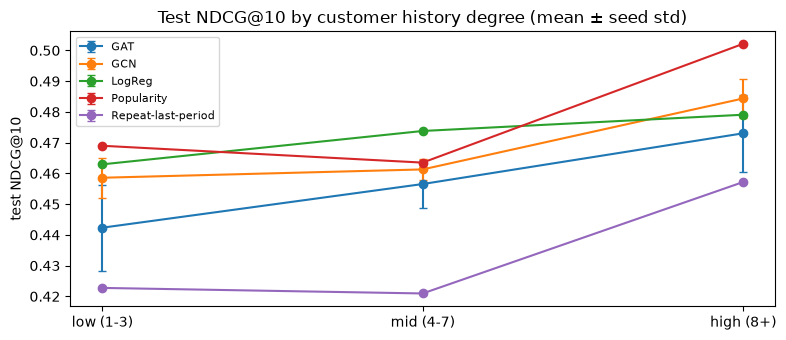

In [73]:
deg_test = np.concatenate([(s['cnt'] > 0).sum(1) for s in SPLIT_SNAPS['test']])
has_pos = Y_TEST.sum(1) > 0
bins = pd.cut(deg_test[has_pos], [0, 3, 7, 17], labels=['low (1-3)', 'mid (4-7)', 'high (8+)'])
print('customer-quarters per bin:', bins.value_counts().sort_index().to_dict())
deg_rows = []
for m in ['Popularity', 'Repeat-last-period', 'LogReg', 'GCN', 'GAT']:
    per_seed = [pd.Series(per_customer_ndcg(S, Y_TEST)).groupby(np.asarray(bins)).mean() for S in TEST_SCORES[m]]
    df_s = pd.concat(per_seed, axis=1)
    for b in df_s.index: deg_rows.append({'model': m, 'degree bin': b, 'NDCG@10': df_s.loc[b].mean(), 'std': df_s.loc[b].std(ddof=0)})
DEG = pd.DataFrame(deg_rows)
piv = DEG.pivot(index='model', columns='degree bin', values='NDCG@10')[['low (1-3)', 'mid (4-7)', 'high (8+)']]
display(piv.round(4))
fig, ax = plt.subplots(figsize=(8, 3.5))
for m in piv.index: ax.errorbar(range(3), piv.loc[m], yerr=DEG.pivot(index='model', columns='degree bin', values='std').loc[m, piv.columns], marker='o', capsize=3, label=m)
ax.set_xticks(range(3)); ax.set_xticklabels(piv.columns); ax.set_ylabel('test NDCG@10'); ax.set_title('Test NDCG@10 by customer history degree (mean ± seed std)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Insight (H2, degree split).** *Expected* GAT to help most for low-degree customers. *Observed:* the opposite of the hypothesis. **GAT is the weakest learned model in every bin**, and its gap to popularity is largest for **low-degree customers** (0.442 vs 0.469, 172 customer-quarters). The GCN sits between GAT and popularity in all bins. Popularity wins the high-degree bin clearly (0.502). Every model does better on high-degree customers, simply because they buy more sub-categories in t+1 (more positives make NDCG easier). With only 1–3 neighbours, attention has almost nothing to choose between, and the extra parameters add noise. **H2 is not supported**: learned weighting does not beat fixed weighting for any degree group.

## Shopping question (H4): what % of customers will buy each sub-category next quarter?

**What:** turn each model's scores into **calibrated probabilities over all eligible customers** (including those who end up buying nothing), then average each column. That gives the predicted **% of customers who buy sub-category c in quarter t+1**, which I compare with the actual %.
- LogReg is trained on all eligible rows, so its outputs are already probabilities.
- GCN/GAT scores come from negative-sampled training, so they are not probabilities. I apply **Platt scaling fitted on the validation snapshots only** (a logistic regression on the logit of the seed-averaged score).
- Two naive forecasters for comparison: **last quarter's rate** and the **same quarter last year** (seasonal naive).

The error is the mean absolute error in percentage points over 17 sub-categories × 3 test quarters.

In [74]:
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
# validation scores (seed-averaged) for Platt scaling - fitted on VAL only
Y_VAL = stack(SPLIT_SNAPS['val'], 'Y')
val_scores = {'GCN': np.mean([gnn_scores(r['model'], SPLIT_SNAPS['val']) for r in FINAL_MODELS['GCN']], 0),
              'GAT': np.mean([gnn_scores(r['model'], SPLIT_SNAPS['val']) for r in FINAL_MODELS['GAT']], 0)}
PLATT = {m: LogisticRegression().fit(logit(val_scores[m]).reshape(-1, 1), Y_VAL.ravel()) for m in val_scores}
def calibrated(m, S):
    if m in PLATT: return PLATT[m].predict_proba(logit(S).reshape(-1, 1))[:, 1].reshape(S.shape)
    return S

rows_pct = []
for k, s in enumerate(SPLIT_SNAPS['test']):
    lo = sum(x['n'] for x in SPLIT_SNAPS['test'][:k]); hi = lo + s['n']
    actual = s['Y'].mean(0) * 100
    prev = SNAP[s['t']]['Y'].mean(0) * 100 if s['t'] in SNAP else None          # rate observed in quarter t (labels of snapshot t)
    seas = SNAP[s['t1'] - 4]['Y'].mean(0) * 100                                 # same quarter one year earlier
    est = {'LogReg': MEAN_SCORES['LogReg'][lo:hi].mean(0) * 100,
           'GCN (Platt)': calibrated('GCN', MEAN_SCORES['GCN'][lo:hi]).mean(0) * 100,
           'GAT (Platt)': calibrated('GAT', MEAN_SCORES['GAT'][lo:hi]).mean(0) * 100,
           'Naive: last quarter': prev, 'Naive: same qtr last year': seas}
    for j in range(N_ITEMS):
        rows_pct.append({'quarter': str(QUARTERS[s['t1']]), 'sub-category': ITEM_NAMES[j], 'actual %': actual[j], **{e: v[j] for e, v in est.items()}})
PCT = pd.DataFrame(rows_pct)
ests = ['LogReg', 'GCN (Platt)', 'GAT (Platt)', 'Naive: last quarter', 'Naive: same qtr last year']
mae = {e: (PCT[e] - PCT['actual %']).abs().mean() for e in ests}
bias = {e: (PCT[e] - PCT['actual %']).mean() for e in ests}
print('Mean absolute error of predicted % buying (percentage points):'); print(pd.DataFrame({'MAE (pp)': mae, 'bias (pp)': bias}).round(3).to_string())
print('\nTotal % of eligible customers buying anything, per test quarter:',
      {str(QUARTERS[s['t1']]): round((s['Y'].sum(1) > 0).mean() * 100, 1) for s in SPLIT_SNAPS['test']})

Mean absolute error of predicted % buying (percentage points):
                           MAE (pp)  bias (pp)
LogReg                        0.988     -0.511
GCN (Platt)                   1.469      0.881
GAT (Platt)                   1.372     -0.653
Naive: last quarter           1.228     -0.726
Naive: same qtr last year     1.239     -0.933

Total % of eligible customers buying anything, per test quarter: {'2014Q2': np.float64(29.6), '2014Q3': np.float64(41.1), '2014Q4': np.float64(40.3)}


**Insight (H4, aggregate accuracy).** All forecasters predict the share of customers buying each sub-category to within about **1–1.5 percentage points**. **LogReg is the most accurate (MAE 0.99 pp)**, ahead of both naive forecasters (1.23–1.24 pp) and the Platt-calibrated GNNs (1.37–1.47 pp). Most forecasters slightly *under*-predict (negative bias), because 2014Q3–Q4 were unusually busy: 41% of eligible customers bought something vs 30% in Q2. The calibrated GCN over-predicts by 0.9 pp. **H4 is supported:** the per-sub-category % of buyers is predictable to about 1 pp. The best tool is the simple LogReg, which learns popularity plus customer activity, not a GNN.

**What next:** the answer table. For each sub-category, the actual vs predicted % of customers buying it per test quarter, using the most accurate model (LogReg), plus a chart.

,category,2014Q2 actual,2014Q2 predicted (GCN),2014Q2 predicted (LogReg),2014Q3 actual,2014Q3 predicted (GCN),2014Q3 predicted (LogReg),2014Q4 actual,2014Q4 predicted (GCN),2014Q4 predicted (LogReg)
sub-category,,,,,,,,,,
Binders,Office Supplies,6.5,8.9,8.9,12.7,10.1,9.1,12.0,14.700000,9.3
Storage,Office Supplies,8.3,6.5,7.9,12.2,9.0,8.1,10.8,15.000000,8.3
Art,Office Supplies,7.6,8.5,8.8,10.4,12.0,9.0,10.6,16.700001,9.2
Phones,Technology,2.7,4.1,3.8,5.0,5.3,4.0,5.9,7.800000,4.1
Machines,Technology,2.7,3.0,2.9,3.3,4.0,3.0,5.1,5.100000,3.1
Paper,Office Supplies,3.6,3.7,3.2,4.2,4.7,3.3,4.7,6.800000,3.4
Supplies,Office Supplies,2.9,2.7,3.1,4.7,3.4,3.2,4.7,4.400000,3.3
Copiers,Technology,3.5,3.9,3.5,5.0,4.5,3.6,4.4,6.300000,3.7
Bookcases,Furniture,3.3,3.0,3.4,6.0,4.0,3.6,4.3,5.100000,3.7


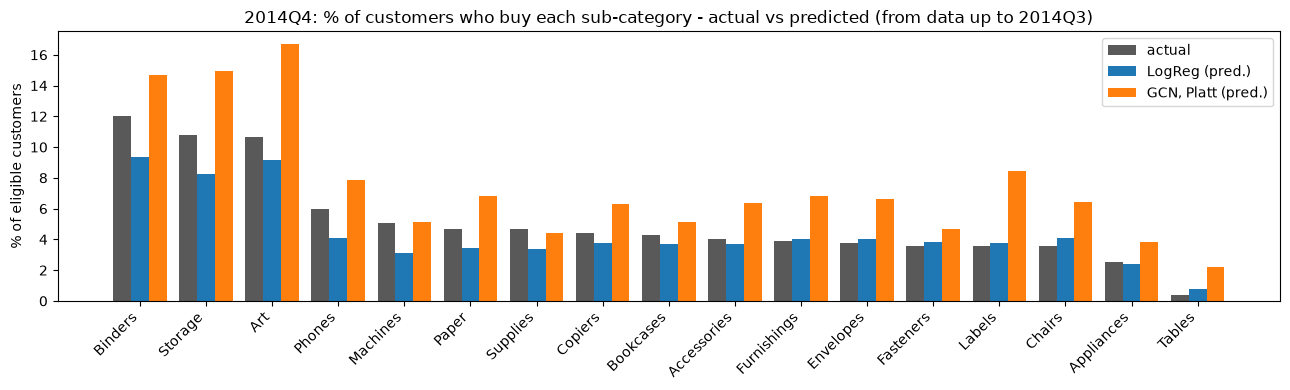

In [75]:
ANSWER = PCT.pivot_table(index='sub-category', columns='quarter', values=['actual %', 'LogReg', 'GCN (Platt)']).round(1)
ANSWER.columns = [f'{q} {"predicted (LogReg)" if m == "LogReg" else ("predicted (GCN)" if m.startswith("GCN") else "actual")}' for m, q in ANSWER.columns]
ANSWER = ANSWER[sorted(ANSWER.columns)]
parent = df.drop_duplicates('Sub-Category').set_index('Sub-Category')['Category']
ANSWER.insert(0, 'category', parent.reindex(ANSWER.index))
ANSWER = ANSWER.sort_values('2014Q4 actual', ascending=False)
display(ANSWER)

q4 = PCT[PCT.quarter == '2014Q4'].set_index('sub-category').loc[ANSWER.index]
fig, ax = plt.subplots(figsize=(13, 4)); x = np.arange(len(q4)); w = .27
ax.bar(x - w, q4['actual %'], w, label='actual', color='0.35'); ax.bar(x, q4['LogReg'], w, label='LogReg (pred.)'); ax.bar(x + w, q4['GCN (Platt)'], w, label='GCN, Platt (pred.)')
ax.set_xticks(x); ax.set_xticklabels(q4.index, rotation=45, ha='right'); ax.set_ylabel('% of eligible customers')
ax.set_title('2014Q4: % of customers who buy each sub-category - actual vs predicted (from data up to 2014Q3)'); ax.legend()
plt.tight_layout(); plt.show()

**Insight (the answer table).** Concretely, for **2014Q4**: **12.0% of customers bought Binders, 10.8% Storage, 10.6% Art**, then a long middle of 3.5–6% each (Phones 5.9%, Machines 5.1%, Paper 4.7%, …). The three Office-Supplies staples are bought by 2–3× more customers than anything else.

Two patterns stand out:
1. **The ranking of sub-categories is stable**: Binders, Storage and Art are top in every quarter. That is why popularity is such a strong ranker.
2. **The level is not stable.** LogReg predicts almost the *same* % every quarter (Binders ≈ 9% in Q2, Q3 and Q4) while actual demand jumps from 6.5% (Q2) to 12–13% (Q3–Q4). The model has **no quarter-of-year feature**, so it cannot anticipate the Q3/Q4 surge. The calibrated GCN partly tracks it in Q4 but overshoots. This motivates H6.

**What next (H5, H6):** (H5) a χ² test of independence of customer **segment × sub-category** on purchase lines, plus Cramér's V as effect size. (H6) the % of customers active per quarter-of-year, a χ² test of active vs quarter-of-year, and a check of whether the sub-category *mix* changes by quarter.

In [76]:
from scipy.stats import chi2_contingency
def cramers_v(ct):
    chi2, p, dof, _ = chi2_contingency(ct); n = ct.values.sum(); r, k = ct.shape
    return chi2, p, dof, np.sqrt(chi2 / (n * (min(r, k) - 1)))

# H5: segment x sub-category (purchase lines)
ct5 = pd.crosstab(df['Segment'], df['Sub-Category'])
chi2, p, dof, v = cramers_v(ct5)
print(f'H5 segment x sub-category: chi2={chi2:.1f}, dof={dof}, p={p:.3g}, Cramer V={v:.3f}')
print((pd.crosstab(df['Segment'], df['Sub-Category'], normalize='index') * 100).round(1).T.assign(max_minus_min=lambda d: d.max(1) - d.min(1)).sort_values('max_minus_min', ascending=False).head(6).to_string())
seg_share = df.drop_duplicates('cust_id')['Segment'].value_counts(normalize=True).mul(100).round(1)
print('\ncustomers per segment (%):', seg_share.to_dict())

# H6: seasonality - share of customers active by quarter-of-year (2012-2014 to avoid the ramp-up year)
act = df[df['Order Date'].dt.year >= 2012].groupby('quarter')['cust_id'].nunique()
elig = pd.Series({q: df[(df.q_idx <= QIDX[q])]['cust_id'].nunique() for q in act.index})
qoy = pd.DataFrame({'active': act, 'eligible': elig}); qoy['qoy'] = [q.quarter for q in qoy.index]
agg = qoy.groupby('qoy')[['active', 'eligible']].sum(); agg['% active'] = (agg.active / agg.eligible * 100).round(1)
ct6 = pd.DataFrame({'active': agg.active, 'inactive': agg.eligible - agg.active})
chi2, p, dof, v = cramers_v(ct6)
print(f'\nH6 active vs quarter-of-year (2012-2014): chi2={chi2:.1f}, dof={dof}, p={p:.3g}, Cramer V={v:.3f}'); print(agg.to_string())
ct6b = pd.crosstab(df[df['Order Date'].dt.year >= 2012]['Order Date'].dt.quarter, df[df['Order Date'].dt.year >= 2012]['Sub-Category'])
chi2, p, dof, v = cramers_v(ct6b)
print(f'H6b sub-category MIX vs quarter-of-year: chi2={chi2:.1f}, dof={dof}, p={p:.3g}, Cramer V={v:.3f}')

H5 segment x sub-category: chi2=39.5, dof=32, p=0.17, Cramer V=0.050
Segment       Consumer  Corporate  Home Office  max_minus_min
Sub-Category                                                 
Storage           13.0       12.3         14.7            2.4
Art               15.0       12.9         14.7            2.1
Phones             5.9        5.9          4.3            1.6
Paper              4.5        4.3          5.7            1.4
Supplies           3.8        4.8          5.1            1.3
Envelopes          4.3        4.8          3.5            1.3

customers per segment (%): {'Consumer': 51.4, 'Corporate': 30.1, 'Home Office': 18.6}

H6 active vs quarter-of-year (2012-2014): chi2=97.5, dof=3, p=5.42e-21, Cramer V=0.106
     active  eligible  % active
qoy                            
1       538      2051      26.2
2       622      2136      29.1
3       852      2223      38.3
4       824      2264      36.4
H6b sub-category MIX vs quarter-of-year: chi2=48.9, dof=48, p=0.437,

/var/folders/x6/13qvtl1n1ksgn9xvx06mdqj00000gn/T/ipykernel_33565/3659447909.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  print((pd.crosstab(df['Segment'], df['Sub-Category'], normalize='index') * 100).round(1).T.assign(max_minus_min=lambda d: d.max(1) - d.min(1)).sort_values('max_minus_min', ascending=False).head(6).to_string())
/var/folders/x6/13qvtl1n1ksgn9xvx06mdqj00000gn/T/ipykernel_33565/3659447909.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  print((pd.crosstab(df['Segment'], df['Sub-Category'], normalize='index') * 100).round(1).T.assign(max_minus_min=lambda d: d.max(1) - d.min(1)).sort_values('max_minus_min', ascending=False).head(6).to_string())


**Insight (H5, H6).**
- **H5 (segment changes what people buy): not supported.** χ² = 39.5, dof 32, **p = 0.17, Cramér's V = 0.05**. Consumers, Corporate and Home Office customers buy the same sub-category mix; the largest difference is 2.4 pp (Storage). Segment is not useful for personalising *what* to recommend.
- **H6 (seasonality): supported for *how many* people buy, not for *what* they buy.** The share of eligible customers who buy anything rises from **26% in Q1 and 29% in Q2 to 38% in Q3 and 36% in Q4** (2012–2014; χ² = 97.5, p = 5e−21, V = 0.11). But the **sub-category mix does not change with season** (p = 0.44, V = 0.05).

*Implication for the shopping question:* to forecast "% of customers buying sub-category c next quarter", what matters is (overall activity, which is seasonal) × (popularity share, which is stable). The models here capture the second well and miss the first. Adding a quarter-of-year feature is the obvious improvement for the % forecasts; it would not change the per-customer rankings.

## Plots explaining how the models work

**Plot 1: degrees, and why GCN normalises by degree.** Using the last test snapshot (history through 2014Q3): customer and sub-category degree distributions, plus a 15-customer × 17-sub-category slice of the adjacency matrix A next to the GCN propagation weights Ã = D^{-1/2}(A+I)D^{-1/2}. Without normalisation, a hub like Binders (degree ~550) would contribute a raw sum hundreds of times larger than Tables (~70). The 1/√(d_i d_j) factor shrinks messages from hubs, so a customer's embedding is not dominated by the most popular items.

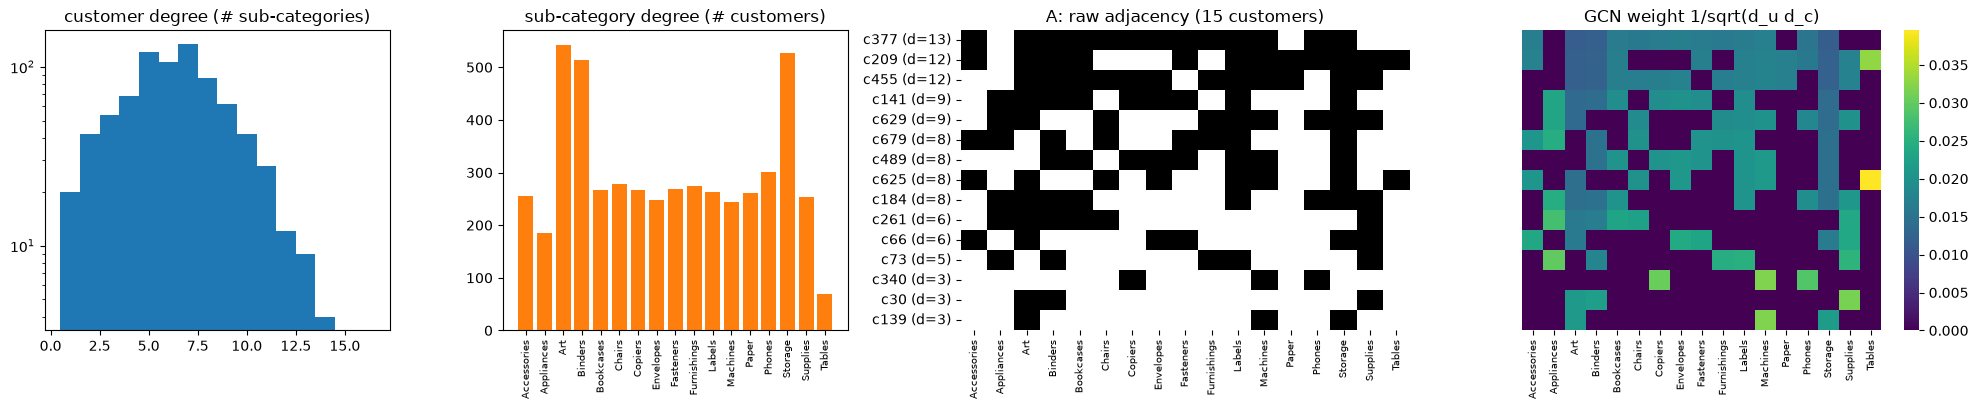

weight range: 0.0111 - 0.0685 | ratio 6.2


In [77]:
S_LAST = SNAP[15]; n = S_LAST['n']
A = np.zeros((n, N_ITEMS)); A[S_LAST['edges'].u, S_LAST['edges'].subcat_id] = 1
du, di = A.sum(1) + 1, A.sum(0) + 1                       # +1: GCN self-loop
W = A / np.sqrt(np.outer(du, di))                           # D^-1/2 A D^-1/2 (customer-item block)
sample = np.random.default_rng(3).choice(n, 15, replace=False); sample = sample[np.argsort(-A[sample].sum(1))]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2), gridspec_kw={'width_ratios': [1, 1, 1.3, 1.3]})
ax[0].hist(A.sum(1), bins=np.arange(0.5, 17.5), color='tab:blue'); ax[0].set_title('customer degree (# sub-categories)'); ax[0].set_yscale('log')
ax[1].bar(range(N_ITEMS), A.sum(0), color='tab:orange'); ax[1].set_xticks(range(N_ITEMS)); ax[1].set_xticklabels(ITEM_NAMES, rotation=90, fontsize=7); ax[1].set_title('sub-category degree (# customers)')
sns.heatmap(A[sample], ax=ax[2], cmap='Greys', cbar=False, xticklabels=ITEM_NAMES, yticklabels=[f'c{c} (d={int(A[c].sum())})' for c in sample]); ax[2].set_title('A: raw adjacency (15 customers)')
sns.heatmap(W[sample], ax=ax[3], cmap='viridis', xticklabels=ITEM_NAMES, yticklabels=False); ax[3].set_title('GCN weight 1/sqrt(d_u d_c)')
for a in ax[2:]: a.tick_params(axis='x', labelsize=7)
plt.tight_layout(); plt.show()
print('weight range:', W[W > 0].min().round(4), '-', W[W > 0].max().round(4), '| ratio', (W[W > 0].max() / W[W > 0].min()).round(1))

**Insight (Plot 1).** The degree shapes match Phase 2. In A, every sampled customer touches 3–11 of 17 sub-categories, and the Art, Binders and Storage columns are almost full. After normalisation the weights range over only **6× (0.011–0.069)**: the largest go to *low-degree customers × low-degree items* (e.g. Tables), and the smallest to busy customers × hub items. GCN thus deliberately upweights rare connections. That is useful when rare connections carry taste, but here (Phase 2) they don't.

**Plot 2: one customer, two weighting schemes.** For one test customer (2014Q4 snapshot, final GAT/GCN with seed 0) I show the weight with which each neighbouring sub-category's message enters the customer's representation. On the left is GCN's fixed weight 1/√(d_u d_c), renormalised to sum to 1 for comparison. On the right is GAT's learned attention α_uc in layer 1 and layer 2, averaged over heads; the self-loop is shown too.

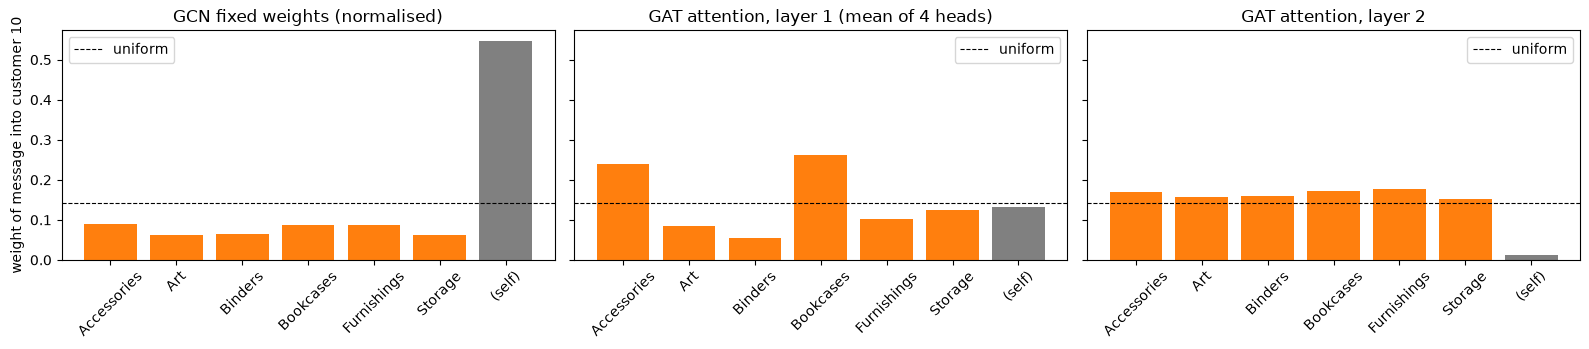

neighbour degrees: {'Accessories': np.int64(255), 'Art': np.int64(543), 'Binders': np.int64(514), 'Bookcases': np.int64(267), 'Furnishings': np.int64(275), 'Storage': np.int64(527)}
GCN : [0.09  0.062 0.064 0.088 0.087 0.063 0.546]
GAT1: [0.239 0.084 0.056 0.262 0.102 0.126 0.131]
GAT2: [0.17  0.157 0.158 0.172 0.178 0.151 0.013]


In [78]:
gat0 = FINAL_MODELS['GAT'][0]['model']; gat0.eval()
with torch.no_grad():
    _, _, _, ATT = gat0.encode(S_LAST, return_att=True)       # list of (edge_index_with_selfloops, alpha [E, heads])
deg_u = A.sum(1)
u = int(np.where(deg_u == 6)[0][0])                         # a typical customer with 6 sub-categories
nbrs = np.where(A[u] > 0)[0]
gcn_w = np.array([1 / np.sqrt((deg_u[u] + 1) * (A[:, c].sum() + 1)) for c in nbrs]); self_w = 1 / (deg_u[u] + 1)
gcn_all = np.append(gcn_w, self_w); gcn_all = gcn_all / gcn_all.sum()
labels = list(ITEM_NAMES[nbrs]) + ['(self)']
def att_into(layer, node):
    ei, a = ATT[layer]; ei = ei.cpu().numpy(); a = a.mean(1).cpu().numpy()
    m = ei[1] == node; src = ei[0][m]; w = a[m]
    out = {}
    for s_, w_ in zip(src, w): out['(self)' if s_ == node else ITEM_NAMES[s_ - n]] = w_
    return np.array([out[l] for l in labels])
att1, att2 = att_into(0, u), att_into(1, u)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for a_, w, t in zip(ax, [gcn_all, att1, att2], ['GCN fixed weights (normalised)', 'GAT attention, layer 1 (mean of 4 heads)', 'GAT attention, layer 2']):
    a_.bar(labels, w, color=['tab:orange'] * len(nbrs) + ['0.5']); a_.axhline(1 / len(labels), ls='--', c='k', lw=.8, label='uniform')
    a_.set_title(t); a_.tick_params(axis='x', rotation=45); a_.legend()
ax[0].set_ylabel(f'weight of message into customer {u}')
plt.tight_layout(); plt.show()
print('neighbour degrees:', dict(zip(ITEM_NAMES[nbrs], A[:, nbrs].sum(0).astype(int))))
print('GCN :', np.round(gcn_all, 3)); print('GAT1:', np.round(att1, 3)); print('GAT2:', np.round(att2, 3))

**Insight (Plot 2).** For customer 10 (6 sub-categories: Accessories, Art, Binders, Bookcases, Furnishings, Storage):
- **GCN** gives the *self-loop* 55% of the weight. Its own term is 1/(d_u+1) = 1/7, while each item term is 1/√(7·~500), which is tiny. The remaining 45% is split by item degree: lower-degree Accessories, Bookcases and Furnishings get ~0.09, the hubs Art, Binders and Storage ~0.06.
- **GAT layer 1** learns a *sharper* and different pattern. It concentrates on **Bookcases (0.26) and Accessories (0.24)**, the low-degree neighbours, nearly ignores Binders (0.06), and gives self only 0.13.
- **GAT layer 2** is almost **uniform** over neighbours (0.15–0.18) and essentially drops the self-loop (0.01).

So GAT does learn non-uniform, input-dependent weights. As the test results showed, though, the extra flexibility doesn't buy accuracy. *Next (Plot 6):* is this typical? Attention distributions over all customers, attention entropy vs degree, and a comparison with uniform attention.

layer 1: mean normalised entropy 0.936 (1 = uniform) | mean max-attention / uniform = 1.89x | corr(item degree, attention) = -0.512
layer 2: mean normalised entropy 0.999 (1 = uniform) | mean max-attention / uniform = 1.08x | corr(item degree, attention) = -0.705


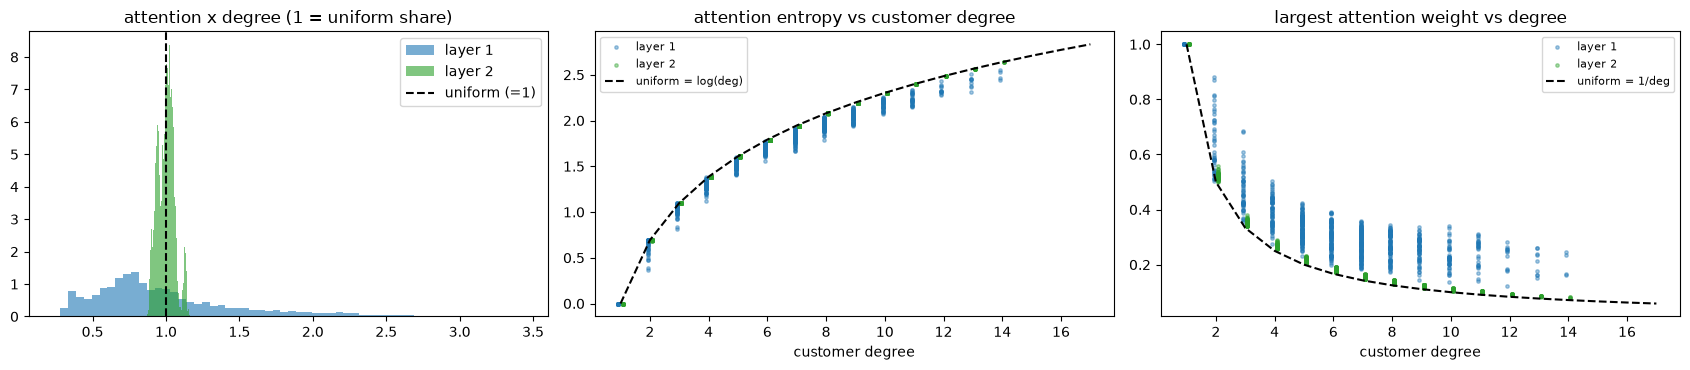

In [79]:
def attention_stats(layer):
    ei, a = ATT[layer]; dst = ei[1].cpu().numpy(); src = ei[0].cpu().numpy(); a = a.mean(1).cpu().numpy()
    d = pd.DataFrame({'dst': dst, 'src': src, 'a': a}); d = d[(d.dst < n) & (d.src != d.dst)]          # messages from items into customers, excl. self-loop
    d['a_norm'] = d.a / d.groupby('dst').a.transform('sum')                                              # renormalise over real neighbours
    g = d.groupby('dst')
    ent = g.a_norm.apply(lambda w: -(w * np.log(w)).sum()); k = g.size()
    return d, pd.DataFrame({'deg': k, 'entropy': ent, 'norm_entropy': ent / np.log(k.clip(lower=2)), 'max_att': g.a_norm.max(), 'uniform': 1 / k})
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
for L, c in [(0, 'tab:blue'), (1, 'tab:green')]:
    d, st = attention_stats(L)
    ax[0].hist(d.a_norm * d.dst.map(st.deg), bins=60, alpha=.6, color=c, label=f'layer {L+1}', density=True)
    ax[1].scatter(st.deg + (L - .5) * .15, st.entropy, s=6, alpha=.4, color=c, label=f'layer {L+1}')
    ax[2].scatter(st.deg + (L - .5) * .15, st.max_att, s=6, alpha=.4, color=c, label=f'layer {L+1}')
    print(f'layer {L+1}: mean normalised entropy {st.norm_entropy[st.deg > 1].mean():.3f} (1 = uniform) | '
          f'mean max-attention / uniform = {(st.max_att / st.uniform)[st.deg > 1].mean():.2f}x | corr(item degree, attention) = '
          f'{np.corrcoef(d.src.map(lambda s: A[:, s - n].sum()), d.a_norm * d.dst.map(st.deg))[0, 1]:+.3f}')
kk = np.arange(1, 18); ax[1].plot(kk, np.log(kk), 'k--', label='uniform = log(deg)'); ax[2].plot(kk, 1 / kk, 'k--', label='uniform = 1/deg')
ax[0].axvline(1, c='k', ls='--', label='uniform (=1)'); ax[0].set_title('attention x degree (1 = uniform share)'); ax[0].legend()
ax[1].set_title('attention entropy vs customer degree'); ax[1].set_xlabel('customer degree'); ax[1].legend(fontsize=8)
ax[2].set_title('largest attention weight vs degree'); ax[2].set_xlabel('customer degree'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Insight (Plot 6, GAT attention).**
- **Layer 1 is mildly non-uniform.** Mean normalised entropy is 0.94 (1 = uniform), and the largest weight averages 1.9× the uniform share. Customers with 2–5 neighbours show the biggest departures, which is visible below the log(deg) curve.
- **Layer 2 is essentially uniform** (entropy 0.999, max = 1.08× uniform). The final layer behaves like mean aggregation.
- **What attention learned is an inverse-popularity weighting.** Attention correlates *negatively* with item degree (r = −0.51 in layer 1, −0.71 in layer 2). GAT rediscovered roughly what GCN's 1/√(d_i d_j) hard-codes: down-weight hub sub-categories. That explains why the two encoders end up statistically tied: the learned weights are close to a reparametrisation of the fixed ones, plus noise.

**Plot 4: over-smoothing.** Left: validation Recall@10 and NDCG@10 vs number of layers (tuning rounds R3/G3). Right: mean pairwise cosine similarity of customer embeddings after each layer, for the 4-layer GCN (R3) and the 3-layer GAT (G3) on the last test snapshot. If embeddings converge (cos → 1), customers become indistinguishable: that is over-smoothing.

GCN, 4 layers (R3)       cos per layer: [0.567 0.514 0.958 0.939 0.993]
GCN, 2 layers (final)    cos per layer: [0.633 0.51  0.977]
GAT, 3 layers (G3)       cos per layer: [0.647 0.558 0.55  0.954]
GAT, 2 layers (final)    cos per layer: [0.68  0.423 0.997]


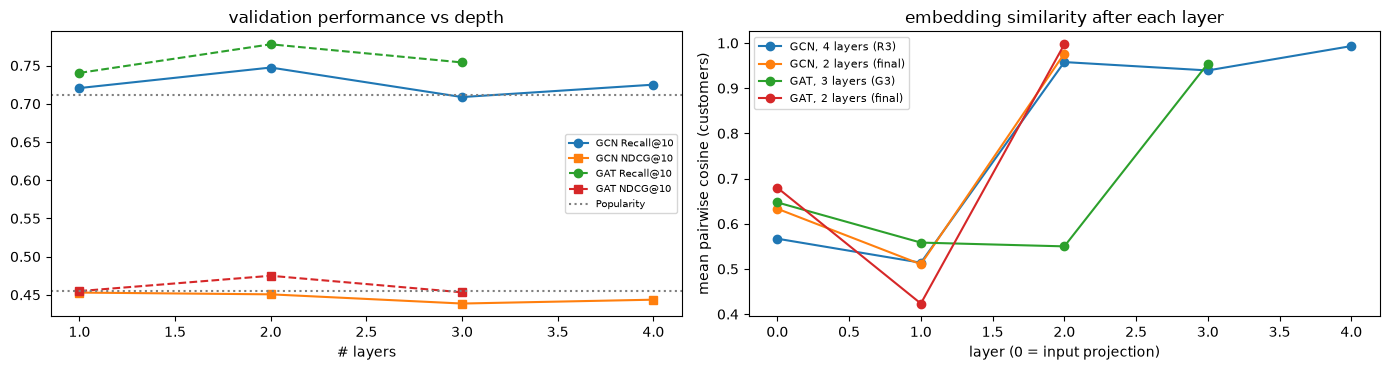

In [80]:
def mean_pairwise_cos(H):
    Hn = F.normalize(H, dim=1); S = Hn @ Hn.T; m = S.shape[0]
    return ((S.sum() - m) / (m * (m - 1))).item()
@torch.no_grad()
def layerwise_cos(model, s):
    model.eval(); _, _, layers_out, _ = model.encode(s, return_layers=True)
    return [mean_pairwise_cos(h[:s['n']]) for h in layers_out]

deep_models = {'GCN, 4 layers (R3)': R3[4]['model'], 'GCN, 2 layers (final)': FINAL_MODELS['GCN'][0]['model'],
               'GAT, 3 layers (G3)': RUN_CACHE[tuple(sorted({**GAT_CUR, 'layers': 3}.items()))]['model'], 'GAT, 2 layers (final)': gat0}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for name, ls in [('GCN', '-'), ('GAT', '--')]:
    sv = SENS[(name, 'layers')]; L = sorted(sv)
    ax[0].plot(L, [sv[l]['Recall@10'] for l in L], ls, marker='o', label=f'{name} Recall@10')
    ax[0].plot(L, [sv[l]['NDCG@10'] for l in L], ls, marker='s', label=f'{name} NDCG@10')
ax[0].axhline(RESULTS_VAL['Popularity']['Recall@10'], c='grey', ls=':'); ax[0].axhline(RESULTS_VAL['Popularity']['NDCG@10'], c='grey', ls=':', label='Popularity')
ax[0].set_xlabel('# layers'); ax[0].set_title('validation performance vs depth'); ax[0].legend(fontsize=7)
for name, m in deep_models.items():
    c = layerwise_cos(m, S_LAST); ax[1].plot(range(len(c)), c, marker='o', label=name); print(f'{name:24s} cos per layer: {np.round(c, 3)}')
ax[1].set_xlabel('layer (0 = input projection)'); ax[1].set_ylabel('mean pairwise cosine (customers)'); ax[1].set_title('embedding similarity after each layer'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Insight (Plot 4, over-smoothing).**
- **Performance vs depth** shows an inverted U: 2 layers is best for both encoders, and 3–4 layers lose 0.02–0.04 Recall@10. That is mild, and within ~2 SE.
- **Embedding similarity tells the bigger story.** After the input projection, customers have mean pairwise cosine 0.57–0.68. **After two hops (customer → sub-category → customer) it jumps to 0.96–1.00 in every model**, and extra layers keep it there (GCN-4: 0.96 → 0.94 → 0.99).
- So over-smoothing appears **at depth 2 already**, not as a gradual effect of depth. With only 17 hub-like item nodes, each densely connected (density 37%), a single customer → item → customer round trip averages over a large share of the graph. Every customer's final embedding points in almost the same direction, which is mathematically why the GNNs' rankings collapse toward a shared, popularity-like ordering.

**Plot 5: UMAP of the final embeddings** (seed 0, last test snapshot). Customers are coloured by their most-bought top-level Category so far; the 17 sub-category nodes are marked with stars and labels.

/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


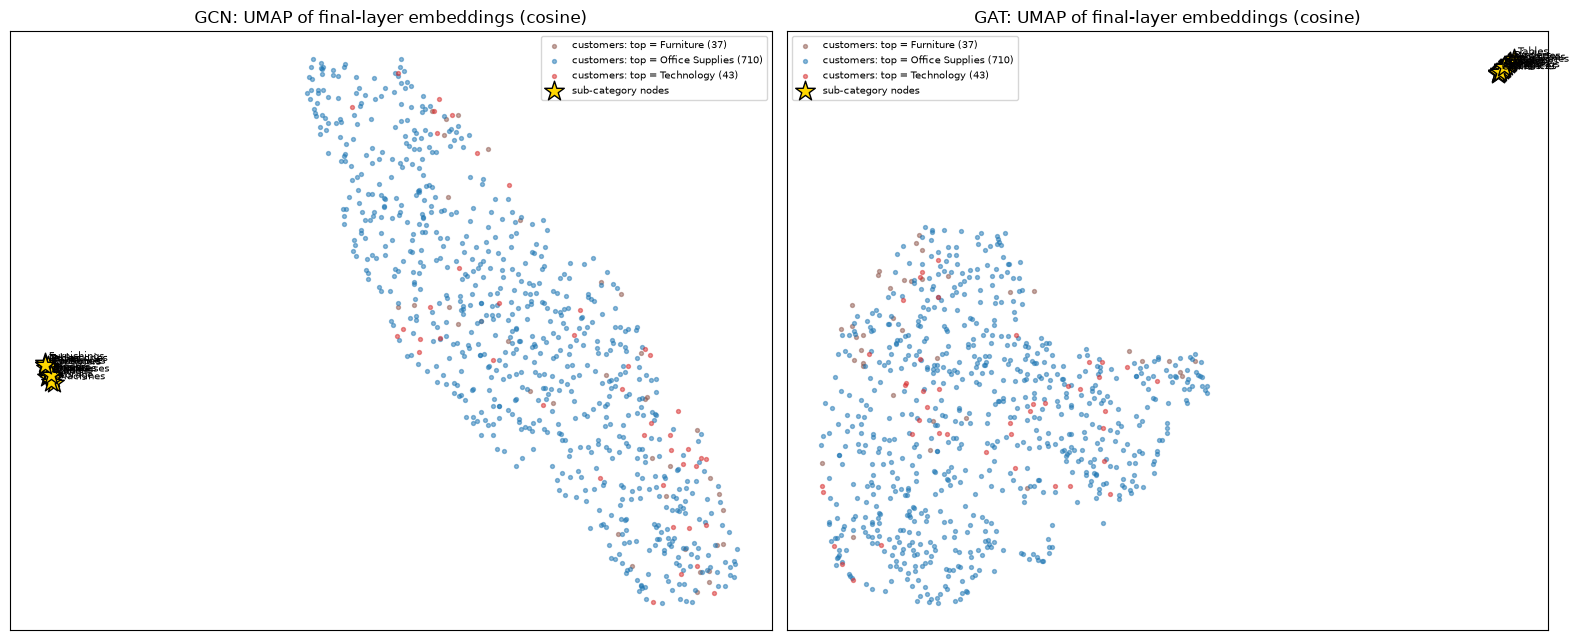

customers per top Category: {'Office Supplies': 710, 'Technology': 43, 'Furniture': 37}


In [81]:
import umap
hist_last = df[df.q_idx <= S_LAST['t']]
top_cat = hist_last.groupby('cust_id')['Category'].agg(lambda s: s.value_counts().idxmax()).reindex(S_LAST['custs']).values
cat_colors = {'Furniture': 'tab:brown', 'Office Supplies': 'tab:blue', 'Technology': 'tab:red'}
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
for a_, (name, model) in zip(ax, [('GCN', FINAL_MODELS['GCN'][0]['model']), ('GAT', gat0)]):
    model.eval()
    with torch.no_grad(): zc, zi = model.encode(S_LAST)[:2]
    Z = torch.cat([zc, zi]).cpu().numpy()
    emb = umap.UMAP(n_neighbors=30, min_dist=0.3, metric='cosine', random_state=SEED).fit_transform(Z)
    for cat, col in cat_colors.items():
        m = top_cat == cat; a_.scatter(emb[:n][m, 0], emb[:n][m, 1], s=8, alpha=.5, c=col, label=f'customers: top = {cat} ({m.sum()})')
    a_.scatter(emb[n:, 0], emb[n:, 1], marker='*', s=220, c='gold', edgecolors='k', label='sub-category nodes')
    for j in range(N_ITEMS): a_.annotate(ITEM_NAMES[j], emb[n + j], fontsize=7, xytext=(3, 3), textcoords='offset points')
    a_.set_title(f'{name}: UMAP of final-layer embeddings (cosine)'); a_.legend(fontsize=7, loc='best'); a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()
print('customers per top Category:', pd.Series(top_cat).value_counts().to_dict())

**Insight (Plot 5).** Two observations:
1. **Customers form one undifferentiated blob** in both models. There are no taste clusters, and colouring by top Category is uninformative because 710 of 790 customers' top Category is Office Supplies. It is the largest category by line count, so it tops almost everyone's history.
2. **Sub-category nodes sit far from all customers** (cosine-UMAP puts them in a separate cluster). That is expected with a dot-product decoder, which only needs the *projection* of customer vectors onto item vectors to rank correctly, not proximity.

The colouring above doesn't explain the blob's layout. *Next:* colour the same GCN customer map by **activity (log #orders)** and by **Segment**, to see what the main axis of variation is.

/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


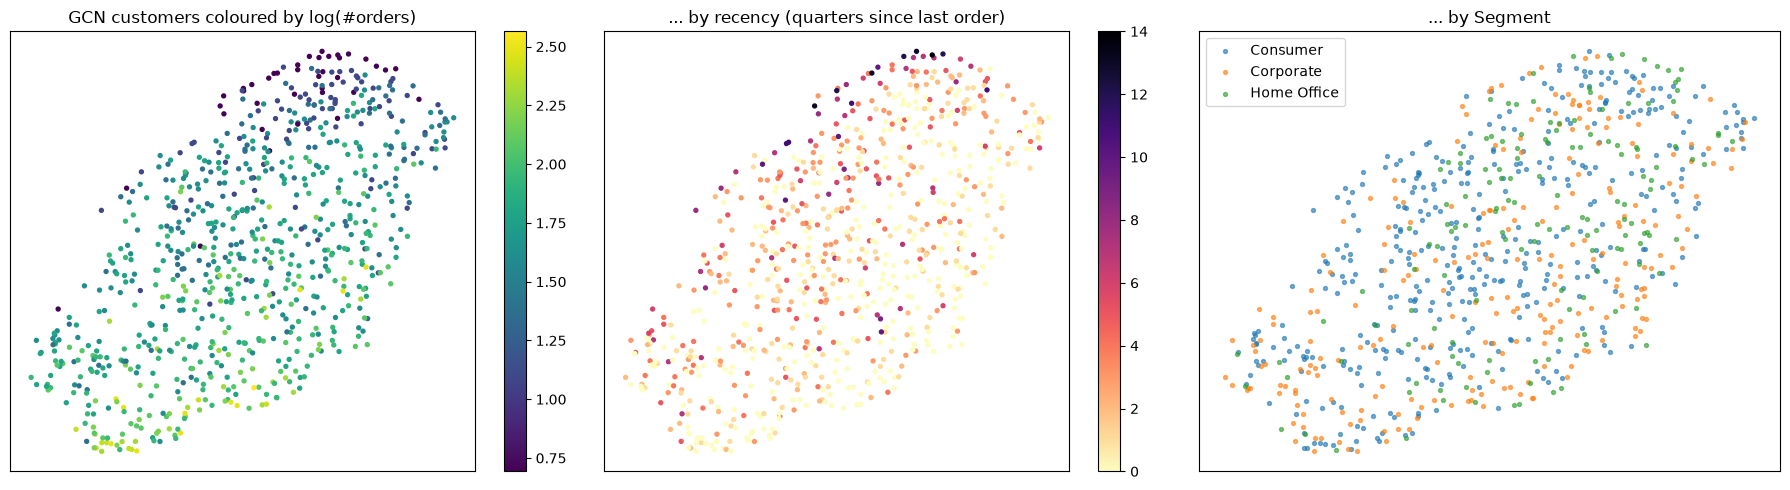

Spearman(UMAP-1, log_orders) = -0.27 | Spearman(UMAP-2, log_orders) = -0.66
Spearman(UMAP-1, recency_q ) = -0.08 | Spearman(UMAP-2, recency_q) = +0.23
Spearman(UMAP-1, n_subcats ) = -0.49 | Spearman(UMAP-2, n_subcats) = -0.94
Spearman(UMAP-1, tenure_q  ) = +0.00 | Spearman(UMAP-2, tenure_q) = -0.27


In [82]:
gcn0 = FINAL_MODELS['GCN'][0]['model']; gcn0.eval()
with torch.no_grad(): zc, zi = gcn0.encode(S_LAST)[:2]
emb_c = umap.UMAP(n_neighbors=30, min_dist=0.3, metric='cosine', random_state=SEED).fit_transform(zc.cpu().numpy())
Xraw = S_LAST['X']
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sc = ax[0].scatter(emb_c[:, 0], emb_c[:, 1], c=Xraw['log_orders'], s=8, cmap='viridis'); plt.colorbar(sc, ax=ax[0]); ax[0].set_title('GCN customers coloured by log(#orders)')
sc = ax[1].scatter(emb_c[:, 0], emb_c[:, 1], c=Xraw['recency_q'], s=8, cmap='magma_r'); plt.colorbar(sc, ax=ax[1]); ax[1].set_title('... by recency (quarters since last order)')
seg = df.drop_duplicates('cust_id').set_index('cust_id')['Segment'].reindex(S_LAST['custs']).values
for s_, c_ in zip(SEGMENTS, ['tab:blue', 'tab:orange', 'tab:green']):
    m = seg == s_; ax[2].scatter(emb_c[m, 0], emb_c[m, 1], s=8, c=c_, alpha=.6, label=s_)
ax[2].set_title('... by Segment'); ax[2].legend()
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()
from scipy.stats import spearmanr
for f in ['log_orders', 'recency_q', 'n_subcats', 'tenure_q']:
    print(f'Spearman(UMAP-1, {f:10s}) = {spearmanr(emb_c[:, 0], Xraw[f])[0]:+.2f} | Spearman(UMAP-2, {f}) = {spearmanr(emb_c[:, 1], Xraw[f])[0]:+.2f}')

**Insight (Plot 5b).** The structure in the customer embedding is **breadth and activity, not taste**. The main UMAP axis tracks the number of distinct sub-categories bought (Spearman −0.94) and the number of orders (−0.66). Recency gives a weak gradient (+0.23), and Segment is completely mixed. The GNN has learned "how much does this customer buy", which shifts the *level* of all 17 scores together, not "what kind of things do they buy". That is consistent with H5 (segment doesn't matter) and Phase 2 (no co-preference structure).

**Plot 7: hyper-parameter sensitivity.** One panel per tuned parameter, showing val Recall@10 (solid) and NDCG@10 (dashed) for GCN and GAT, with the popularity reference.

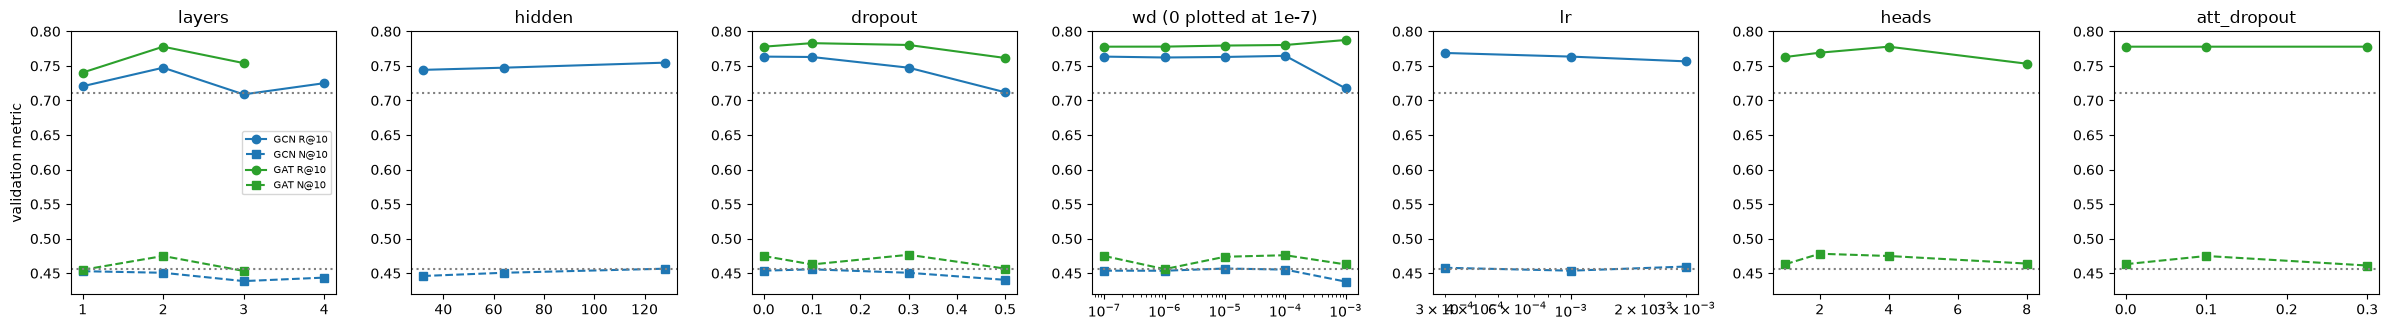

GCN layers      : Recall@10 range 0.039
GCN hidden      : Recall@10 range 0.010
GCN dropout     : Recall@10 range 0.052
GCN wd          : Recall@10 range 0.047
GCN lr          : Recall@10 range 0.012
GAT heads       : Recall@10 range 0.025
GAT layers      : Recall@10 range 0.037
GAT att_dropout : Recall@10 range 0.000
GAT dropout     : Recall@10 range 0.021
GAT wd          : Recall@10 range 0.010


In [83]:
params_order = [('layers', False), ('hidden', False), ('dropout', False), ('wd', True), ('lr', True), ('heads', False), ('att_dropout', False)]
fig, axes = plt.subplots(1, len(params_order), figsize=(24, 3.4))
for a_, (p, logx) in zip(axes, params_order):
    for name, col in [('GCN', 'tab:blue'), ('GAT', 'tab:green')]:
        if (name, p) not in SENS: continue
        sv = SENS[(name, p)]; xs = sorted(sv); xplot = [max(x, 1e-7) for x in xs] if logx else xs
        a_.plot(xplot, [sv[x]['Recall@10'] for x in xs], '-o', c=col, label=f'{name} R@10')
        a_.plot(xplot, [sv[x]['NDCG@10'] for x in xs], '--s', c=col, label=f'{name} N@10')
    a_.axhline(RESULTS_VAL['Popularity']['Recall@10'], c='grey', ls=':'); a_.axhline(RESULTS_VAL['Popularity']['NDCG@10'], c='grey', ls=':')
    if logx: a_.set_xscale('log')
    a_.set_title(p + (' (0 plotted at 1e-7)' if p == 'wd' else '')); a_.set_ylim(0.42, 0.80)
axes[0].legend(fontsize=7); axes[0].set_ylabel('validation metric')
plt.tight_layout(); plt.show()
for (name, p), sv in SENS.items():
    r = [v['Recall@10'] for v in sv.values()]; print(f'{name} {p:12s}: Recall@10 range {max(r) - min(r):.3f}')

**Insight (Plot 7, sensitivity).** Every curve is **flat relative to noise**. The largest Recall@10 ranges are GCN dropout (0.052, driven by 0.5 being harmful), GCN wd (0.047, driven by 1e-3 being harmful) and depth (~0.04). Width, lr, heads, attention dropout and GAT wd each move Recall@10 by ≤ 0.025. NDCG@10 barely moves anywhere (±0.02). The only reliable lessons are *don't over-regularise* (dropout 0.5, wd 1e-3) and *2 layers*. Nothing else matters, as expected when the achievable signal is just popularity plus activity.

**Plot 8: predicted vs actual for 30 test customers** (2014Q4, customers who bought something; seed-averaged GCN scores and LogReg probabilities). Each row is a customer and each column a sub-category; black dots mark actual purchases.

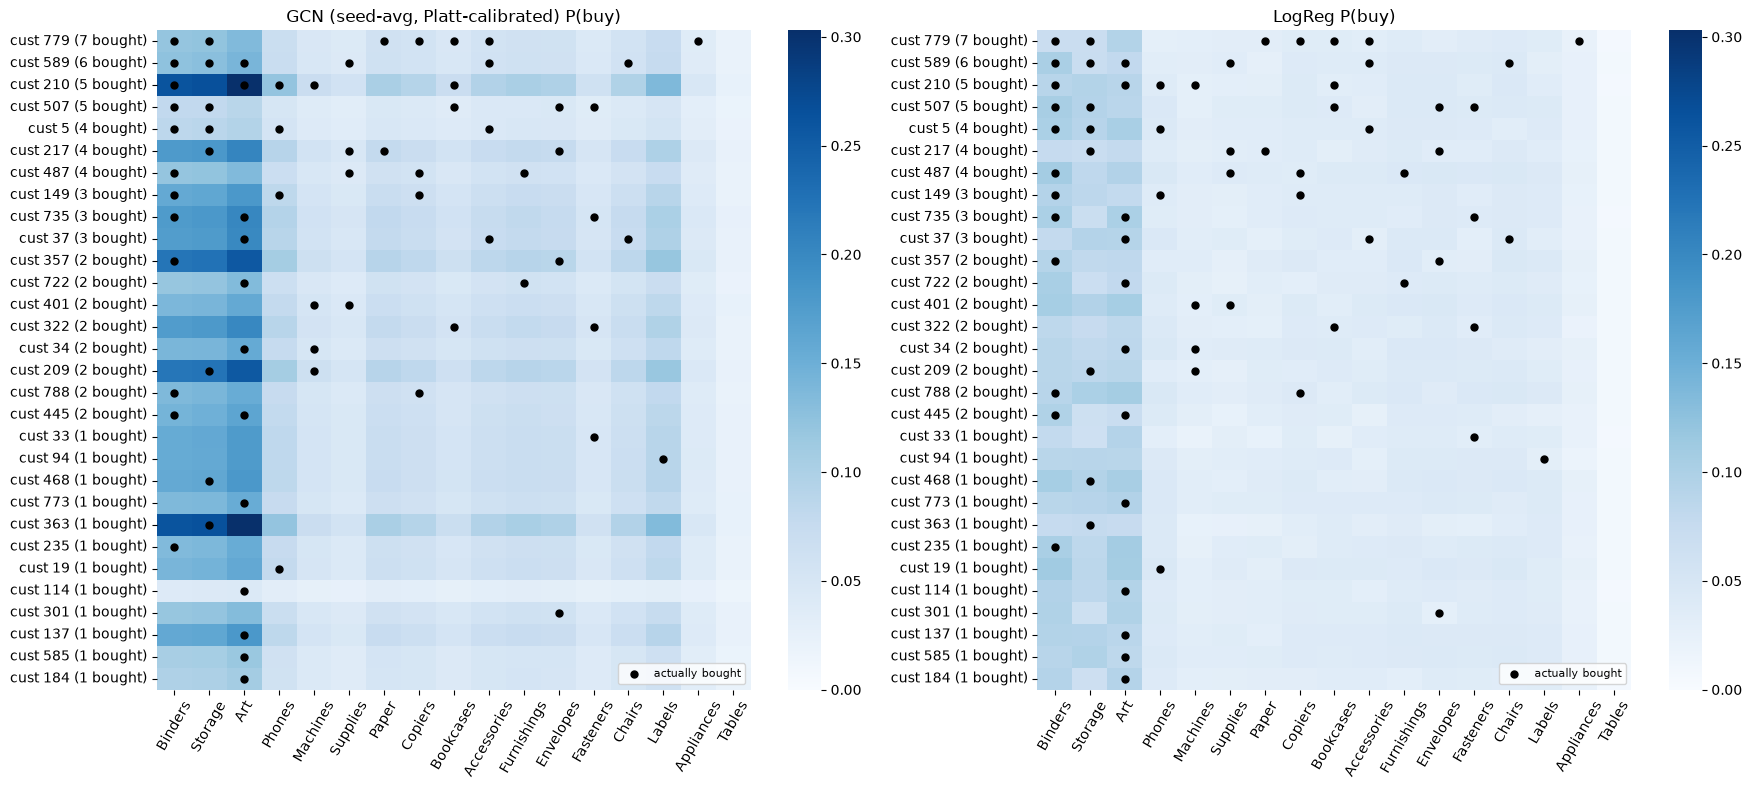

mean correlation of each customer row of GCN score row with the average row (=popularity shape): 0.998
hit rate of each customer top-3 (GCN): 0.623


In [84]:
lo = sum(s['n'] for s in SPLIT_SNAPS['test'][:2]); hi = lo + SPLIT_SNAPS['test'][2]['n']
Y4 = Y_TEST[lo:hi]; G4 = calibrated('GCN', MEAN_SCORES['GCN'][lo:hi]); L4 = MEAN_SCORES['LogReg'][lo:hi]
buyers = np.where(Y4.sum(1) > 0)[0]; pick = np.random.default_rng(5).choice(buyers, 30, replace=False)
pick = pick[np.argsort(-Y4[pick].sum(1))]
col_order = np.argsort(-Y4.mean(0))
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a_, P, t in zip(ax, [G4, L4], ['GCN (seed-avg, Platt-calibrated) P(buy)', 'LogReg P(buy)']):
    sns.heatmap(P[pick][:, col_order], ax=a_, cmap='Blues', vmin=0, vmax=max(G4[pick].max(), L4[pick].max()),
                xticklabels=ITEM_NAMES[col_order], yticklabels=[f'cust {SPLIT_SNAPS["test"][2]["custs"][i]} ({Y4[i].sum()} bought)' for i in pick])
    yy, xx = np.where(Y4[pick][:, col_order] == 1); a_.scatter(xx + .5, yy + .5, c='k', s=25, marker='o', label='actually bought')
    a_.set_title(t); a_.tick_params(axis='x', rotation=60); a_.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()
row_corr = np.mean([np.corrcoef(G4[i], G4.mean(0))[0, 1] for i in pick])
print(f'mean correlation of each customer row of GCN score row with the average row (=popularity shape): {row_corr:.3f}')
print('hit rate of each customer top-3 (GCN):', np.mean([Y4[i][np.argsort(-G4[i])[:3]].sum() > 0 for i in buyers]).round(3))

**Insight (Plot 8).** This is the clearest picture of what the models do. **Every row looks the same**: dark on Binders, Storage and Art, light elsewhere, with only the overall intensity changing by customer (busier customers are darker). The mean correlation between a customer's GCN score row and the average row is **0.998**, so the GCN outputs essentially *popularity × customer activity*. LogReg shows the same pattern. Actual purchases (dots) are scattered across all 17 columns with no visible link to the customer's row. Many purchases fall in the light middle columns that *no* model ranks highly. Still, 62% of buying customers have at least one hit in their top-3, mostly from the three staples.

**Plot 9: final comparison.** Test Recall@10, NDCG@10 and PR-AUC for every model, mean ± seed std (5 seeds).

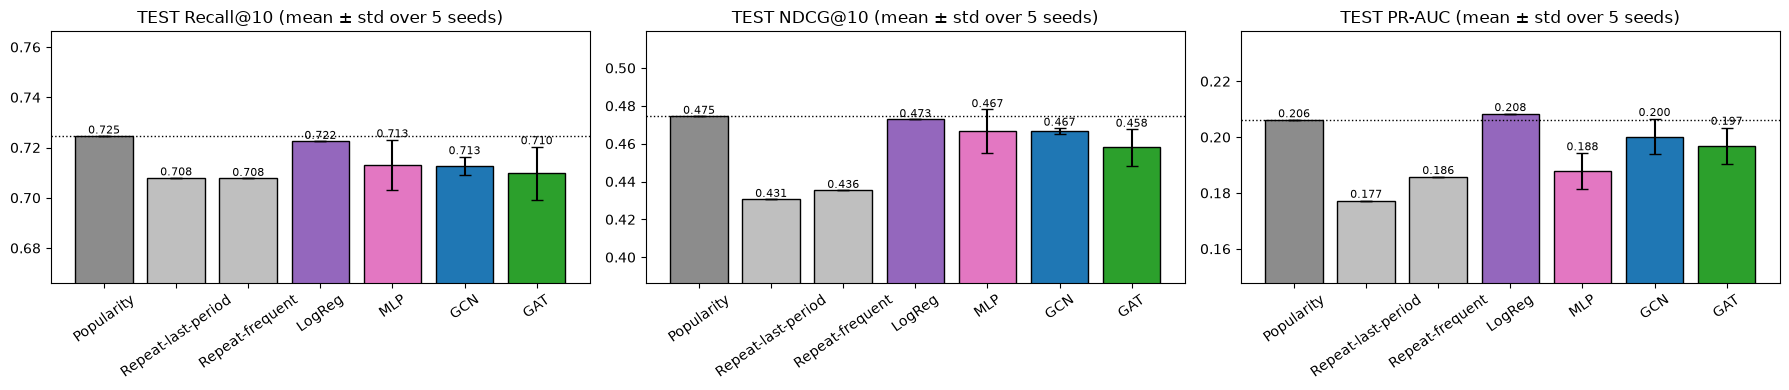

In [85]:
order_m = ['Popularity', 'Repeat-last-period', 'Repeat-frequent', 'LogReg', 'MLP', 'GCN', 'GAT']
colors = ['0.55', '0.75', '0.75', 'tab:purple', 'tab:pink', 'tab:blue', 'tab:green']
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a_, k in zip(ax, ['Recall@10', 'NDCG@10', 'PR-AUC']):
    mu = [MEAN[m][k] for m in order_m]; sd = [STD[m][k] for m in order_m]
    a_.bar(order_m, mu, yerr=sd, capsize=4, color=colors, edgecolor='k')
    a_.axhline(MEAN['Popularity'][k], c='k', ls=':', lw=1)
    lo_ = min(mu) - 3 * max(sd) - .01; a_.set_ylim(lo_, max(mu) + 3 * max(sd) + .01)
    for i, (m_, s_) in enumerate(zip(mu, sd)): a_.text(i, m_ + s_ + .001, f'{m_:.3f}', ha='center', fontsize=8)
    a_.set_title(f'TEST {k} (mean ± std over 5 seeds)'); a_.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.show()

**Insight (Plot 9).** The bar chart summarises the test result: **popularity (grey) is the bar to beat, and nothing beats it.** LogReg ties it, GCN, GAT and MLP sit slightly below with overlapping error bars, and the repeat heuristics are clearly worst on NDCG@10 and PR-AUC. *(Y-axes are zoomed to make sub-0.02 differences visible; they do not start at 0.)*

*Next:* add the final test results to the Experiment Log at the top, then write the Findings.

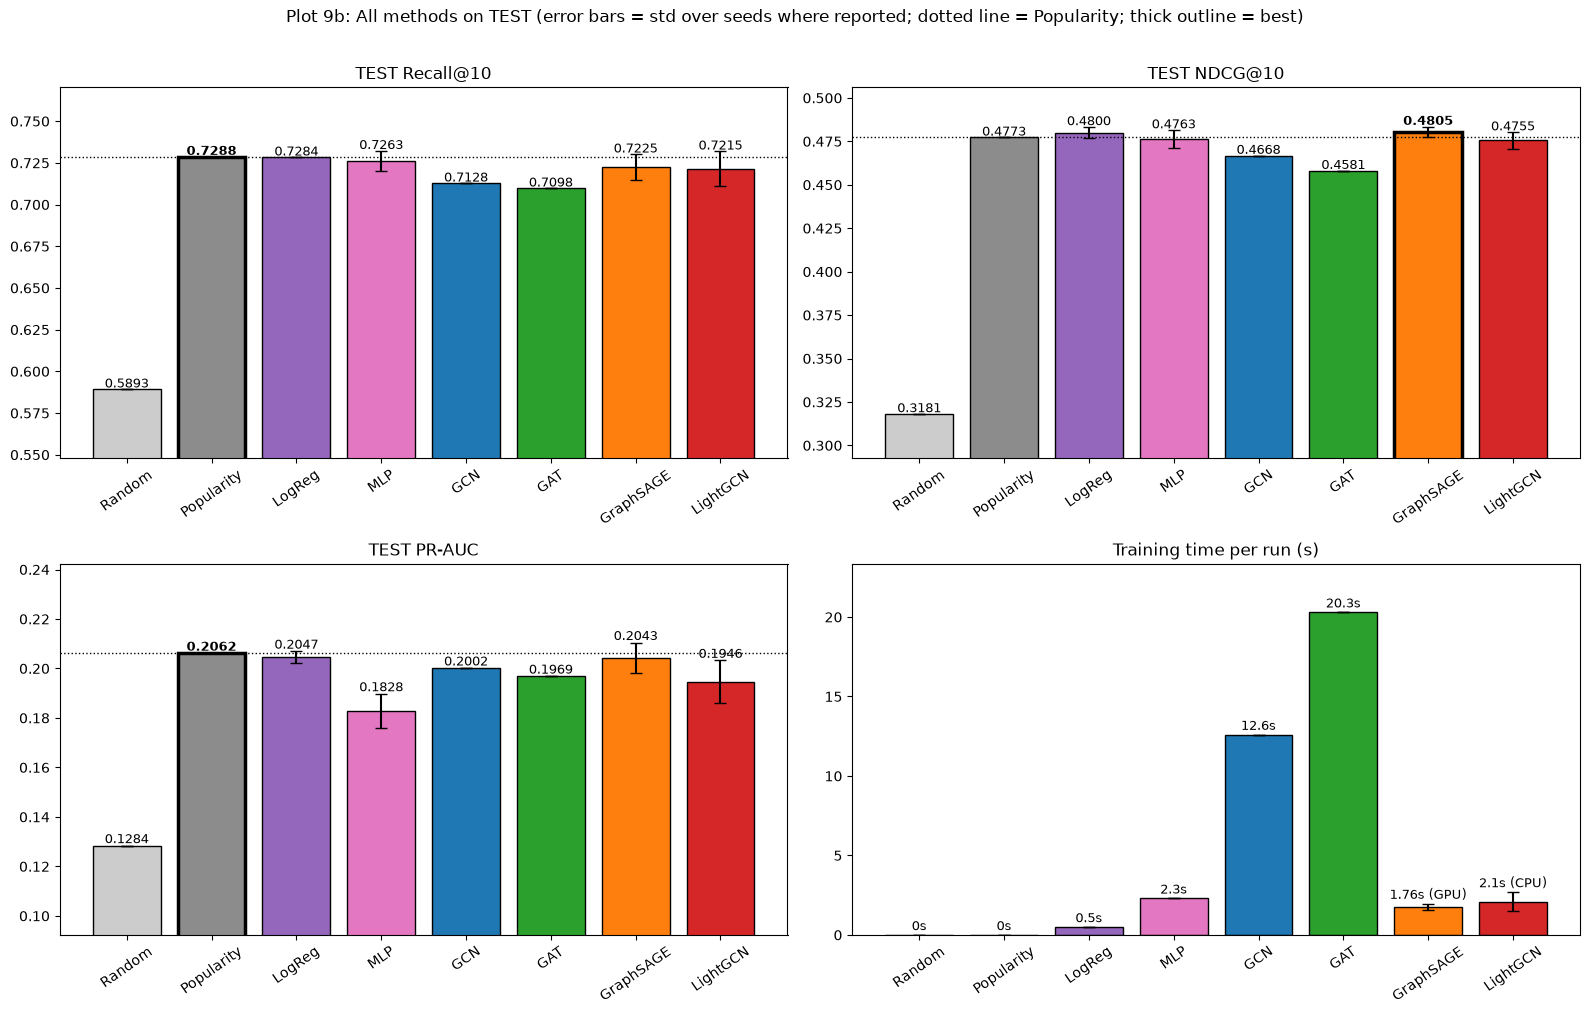

,Description,Device,Recall@10,NDCG@10,PR-AUC,Training time
Method,,,,,,
Random,Untrained baseline: random ranking of sub-cate...,,0.5893,0.3181,0.1284,0.0 s
Popularity,"Heuristic baseline, no training: recommends th...",,0.7288,0.4773,0.2062,0.0 s
LogReg,Learned non-graph baseline; customer features ...,,0.7284,0.4800 ± 0.0033,0.2047 ± 0.0023,0.5 s
MLP,Learned non-graph baseline; customer features ...,,0.7263 ± 0.0060,0.4763 ± 0.0052,0.1828 ± 0.0070,2.3 s
GCN,"2 layers, 64 dims, no dropout",,0.7128,0.4668,0.2002,12.6 s
GAT,"2 layers, 4 heads, 64 dims, attention dropout 0.1",,0.7098,0.4581,0.1969,20.3 s
GraphSAGE,"4 layers, max aggr, 128 hidden / 32 out, GELU,...",GPU,0.7225 ± 0.0077,0.4805 ± 0.0030,0.2043 ± 0.0062,1.76 ± 0.21 s
LightGCN,"4 prop layers, 32-dim emb, lr 1.0, wd 1e-4, no...",CPU,0.7215 ± 0.0105,0.4755 ± 0.0048,0.1946 ± 0.0087,2.10 ± 0.60 s


In [4]:
# Plot 9b: TEST comparison of ALL methods (adds GraphSAGE & LightGCN) + training time
import pandas as pd
import matplotlib.pyplot as plt

# Final TEST numbers per method; *_sd = std over seeds where reported (0 = single value reported)
ALL = pd.DataFrame([
    # Method,       Best params / baseline description,                                                                                 R@10,   sd,     NDCG@10, sd,     PR-AUC, sd,     Train(s), sd,   device
    ['Random',     'Untrained baseline: random ranking of sub-categories',                                                               0.5893, 0.0,    0.3181, 0.0,    0.1284, 0.0,    0.0,  0.0,  ''],
    ['Popularity', 'Heuristic baseline, no training: recommends the most-bought sub-categories to everyone, same order',                 0.7288, 0.0,    0.4773, 0.0,    0.2062, 0.0,    0.0,  0.0,  ''],
    ['LogReg',     'Learned non-graph baseline; customer features and history',                                                          0.7284, 0.0,    0.4800, 0.0033, 0.2047, 0.0023, 0.5,  0.0,  ''],
    ['MLP',        'Learned non-graph baseline; customer features and history',                                                          0.7263, 0.0060, 0.4763, 0.0052, 0.1828, 0.0070, 2.3,  0.0,  ''],
    ['GCN',        '2 layers, 64 dims, no dropout',                                                                                   0.7128, 0.0,    0.4668, 0.0,    0.2002, 0.0,    12.6, 0.0,  ''],
    ['GAT',        '2 layers, 4 heads, 64 dims, attention dropout 0.1',                                                               0.7098, 0.0,    0.4581, 0.0,    0.1969, 0.0,    20.3, 0.0,  ''],
    ['GraphSAGE',  '4 layers, max aggr, 128 hidden / 32 out, GELU, residual, LayerNorm, dropout 0.1',                                 0.7225, 0.0077, 0.4805, 0.0030, 0.2043, 0.0062, 1.76, 0.21, 'GPU'],
    ['LightGCN',   '4 prop layers, 32-dim emb, lr 1.0, wd 1e-4, no node features, no dropout',                                        0.7215, 0.0105, 0.4755, 0.0048, 0.1946, 0.0087, 2.1,  0.6,  'CPU'],
], columns=['Method', 'Description', 'Recall@10', 'Recall@10_sd', 'NDCG@10', 'NDCG@10_sd', 'PR-AUC', 'PR-AUC_sd', 'Train (s)', 'Train (s)_sd', 'Device'])

colors_all = {'Random': '0.8', 'Popularity': '0.55', 'LogReg': 'tab:purple', 'MLP': 'tab:pink', 'GCN': 'tab:blue',
              'GAT': 'tab:green', 'GraphSAGE': 'tab:orange', 'LightGCN': 'tab:red'}
cols = [colors_all[m] for m in ALL['Method']]
pop = ALL.set_index('Method').loc['Popularity']

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
ax = ax.ravel()  # [0] Recall@10, [1] NDCG@10, [2] PR-AUC, [3] Training time
for a_, k in zip(ax[:3], ['Recall@10', 'NDCG@10', 'PR-AUC']):
    mu, sd = ALL[k].values, ALL[k + '_sd'].values
    a_.bar(ALL['Method'], mu, yerr=sd, capsize=4, color=cols, edgecolor='k')
    a_.axhline(pop[k], c='k', ls=':', lw=1, label='Popularity')
    best = mu.argmax()
    a_.patches[best].set_linewidth(2.5)  # thick outline = best on this metric
    lo_ = min(mu) - 3 * max(sd) - .01
    a_.set_ylim(lo_, max(mu) + 3 * max(sd) + .01)
    for i, (m_, s_) in enumerate(zip(mu, sd)):
        a_.text(i, m_ + s_ + .001, f'{m_:.4f}', ha='center', fontsize=9, fontweight='bold' if i == best else 'normal')
    a_.set_title(f'TEST {k}')
    a_.tick_params(axis='x', rotation=35)

# Training time panel
t, tsd = ALL['Train (s)'].values, ALL['Train (s)_sd'].values
ax[3].bar(ALL['Method'], t, yerr=tsd, capsize=4, color=cols, edgecolor='k')
for i, (t_, s_, d_) in enumerate(zip(t, tsd, ALL['Device'])):
    ax[3].text(i, t_ + s_ + .3, f'{t_:g}s' + (f' ({d_})' if d_ else ''), ha='center', fontsize=9)
ax[3].set_ylim(0, t.max() * 1.15)
ax[3].set_title('Training time per run (s)')
ax[3].tick_params(axis='x', rotation=35)

fig.suptitle('Plot 9b: All methods on TEST (error bars = std over seeds where reported; dotted line = Popularity; thick outline = best)', y=1.01)
plt.tight_layout(); plt.show()

# Summary table
tbl = ALL[['Method', 'Description', 'Device']].copy()
for k in ['Recall@10', 'NDCG@10', 'PR-AUC']:
    tbl[k] = [f'{m:.4f} ± {s:.4f}' if s else f'{m:.4f}' for m, s in zip(ALL[k], ALL[k + '_sd'])]
tbl['Training time'] = [f'{m:.2f} ± {s:.2f} s' if s else f'{m:.1f} s' for m, s in zip(ALL['Train (s)'], ALL['Train (s)_sd'])]
display(tbl.set_index('Method'))


In [86]:
test_rows = ['', '**Final TEST results (targets 2014Q2–Q4, 872 customer-quarters; mean ± std over 5 seeds):**', '',
             '| Model | Test Recall@10 | Test NDCG@10 | Test PR-AUC | Params | Verdict vs Popularity (gap > seed std) |', '|---|---|---|---|---|---|']
for m in order_m:
    v = ' / '.join(better(m, 'Popularity', k)[2] for k in ['Recall@10', 'NDCG@10', 'PR-AUC']) if m != 'Popularity' else 'reference'
    test_rows.append(f"| {m} | {MEAN[m]['Recall@10']:.4f} ± {STD[m]['Recall@10']:.4f} | {MEAN[m]['NDCG@10']:.4f} ± {STD[m]['NDCG@10']:.4f} | {MEAN[m]['PR-AUC']:.4f} ± {STD[m]['PR-AUC']:.4f} | {PARAMS[m]:,} | {v} |")
EXP_MD = exp_log_markdown(test_rows)
print(EXP_MD)

## Experiment Log

*Validation set (targets 2013Q4–2014Q1, 445 customers). Adoption rule: change kept only if val Recall@10 improves by ≥ 0.01. Reference: Popularity R@10 0.711 / NDCG@10 0.456 / PR-AUC 0.186.*

| Round | Model | Change | Val Recall@10 | Val NDCG@10 | Val PR-AUC | Conclusion |
|---|---|---|---|---|---|---|
| R1 | GCN | baseline (2L, d64, drop .3, lr 1e-3) | 0.7474 | 0.4506 | 0.1848 | reference |
| R2 | GCN | edge_weight = log(1+#orders) | 0.7485 | 0.4506 | 0.1840 | no gain (+0.001) -> keep unweighted |
| R3 | GCN | layers = 1 | 0.7205 | 0.4529 | 0.1798 |  |
| R3 | GCN | layers = 3 | 0.7088 | 0.4386 | 0.1804 |  |
| R3 | GCN | layers = 4 | 0.7250 | 0.4436 | 0.1749 | no gain >= .01 -> keep 2 layers |
| R4 | GCN | hidden = 32 | 0.7443 | 0.4460 | 0.1795 |  |
| R4 | GCN | hidden = 128 | 0.7547 | 0.4565 | 0.1843 | +0.007 < .01 -> keep d=64 |
| R5 | GCN | dropout = 0.0 | 0.7634 | 0.4537 | 0.1848 |  |
| R5 | GCN | dropout = 0.1 | 0.7629 | 0.4556 | 0.1848 |  |
| R5 | GCN | dropou

# Findings

**Setup recap.** EuroMart orders 2011–2014 (8,042 lines, 792 customers). Customer × **sub-category** (17) bipartite graph, **quarterly** snapshots G_t → targets Y_{t+1}, leakage-checked split (train targets 2011Q2–2013Q3, val 2013Q4–2014Q1, test 2014Q2–Q4). All model choices were made on validation; test was used once, with 5 seeds.

### Hypothesis scorecard

| ID | Hypothesis | Verdict | Evidence |
|---|---|---|---|
| H1 | Graph structure (GCN/GAT) beats non-graph baselines | ❌ **Not supported** | Test NDCG@10: Popularity 0.475, LogReg 0.473, GCN 0.467 ± .002, GAT 0.458 ± .010. Bootstrap CIs vs popularity all include 0 or lie below it |
| H2 | GAT's learned weights beat GCN's fixed weights, esp. for low-degree nodes | ❌ **Not supported** | GAT − GCN NDCG@10 = +0.005, CI [−0.003, +0.012]. GAT is *weakest* on low-degree customers (0.442 vs GCN 0.459) |
| H3 | Own history raises the chance of rebuying a sub-category | ❌ **NoT supported** | Controlled odds ratio 1.01, 95% CI [0.94, 1.09]. Repeat baselines are the worst models |
| H4 | The % of customers buying each sub-category next quarter is predictable | ✅ **Supported** | MAE ≈ 1.0 pp (LogReg), 1.2 pp (naive), 1.4–1.5 pp (GNNs, Platt-calibrated) |
| H5 | Customer segment changes what people buy | ❌ **Not supported** | χ² p = 0.17, Cramér's V = 0.05 |
| H6 | Purchasing is seasonal | ✅ **For volume, not mix** | % active: Q1 26%, Q2 29%, Q3 38%, Q4 36% (p = 5e−21); sub-category mix by season p = 0.44 |

### The shopping answer: what % of customers will buy each sub-category next quarter?
In **2014Q4**, out of all customers seen before: **Binders 12.0%, Storage 10.8%, Art 10.6%**, then Phones 5.9%, Machines 5.1%, Paper 4.7%, Supplies 4.7%, Copiers 4.4%, Bookcases 4.3%, Accessories 4.1%, Furnishings 3.9%, Envelopes 3.8%. The full table for all 17 sub-categories and all three test quarters is in the H4 section above. These shares can be forecast to about **±1 percentage point**. The *ranking* of sub-categories is very stable; the *level* rises about 1.4× in Q3/Q4. In practice: forecast % buying c ≈ (seasonal share of customers active) × (stable popularity share of c). For an individual customer, the best available prediction is the same popularity ranking scaled by how much that customer buys.

### 1. Does graph structure beat the non-graph baselines?
**No.** On test, **Popularity is the best ranker** (Recall@10 0.725, NDCG@10 0.475, PR-AUC 0.206), and LogReg ties it. The GCN (0.713 / 0.467 / 0.200) and GAT (0.710 / 0.458 / 0.197) are slightly *below* it: "worse" by the seed-std rule, and "no detectable difference" by a customer bootstrap. Both GNNs do beat repeat-last-period (NDCG@10 0.431) and repeat-frequent. The apparent validation gains (GCN +0.05, GAT +0.07 Recall@10 over popularity) **did not survive the 5-seed test**: they were selection optimism from one seed and ~40 configurations on a 445-customer validation set.

### 2. Does GAT's learned weighting beat GCN's fixed weighting, and for which nodes?
**No, for no group of nodes.** GAT − GCN on test NDCG@10 is +0.005 (CI [−0.003, +0.012]) on seed-averaged scores, and GAT has 2.2× the parameters and 3× the seed variance. By degree: low-degree customers (1–3 sub-categories) GAT 0.442 vs GCN 0.459; mid 0.457 vs 0.461; high 0.473 vs 0.484. **What attention learned** (Plot 6): layer 1 is mildly selective (entropy 0.94 of uniform), layer 2 is uniform (0.999), and the weights correlate *negatively* with item degree (r = −0.51 / −0.71). In other words, it rediscovered GCN's down-weighting of hub items. With identical inductive bias in practice, the extra freedom only adds variance.

### 3. How much did each tuning step help? (validation Recall@10, adoption threshold +0.01)
| Step | GCN Δ | Adopted? | GAT step | GAT Δ | Adopted? |
|---|---|---|---|---|---|
| R2 edge weight log(1+count) | +0.001 | no | — | — | — |
| R3 layers {1–4} | 0 (2 best) | keep 2 | G3 layers {1–3} | 0 (2 best) | keep 2 |
| R4 hidden {32, 64, 128} | +0.007 (128) | no | G2 heads {1, 2, 4, 8} | 0 (4 best) | keep 4 |
| R5 dropout {0, .1, .3, .5} | **+0.016 (0)** | **yes** | G5 dropout | +0.005 | no |
| R6 weight decay | +0.001 | no | G6 weight decay | +0.010 (1e-3, NDCG ↓) | no |
| R7 learning rate | +0.005 | no | G4 attention dropout | 0 | keep 0.1 |

Total tuning gain: GCN **+0.016 Recall@10, +0.003 NDCG@10** on validation; GAT **0**. The only reliable lessons were *don't over-regularise* (dropout 0.5 and wd 1e-3 hurt) and *use 2 layers*. Two **protocol** fixes mattered more than any hyper-parameter: (a) a corrected degree-preserving null in Phase 2, and (b) a 50-epoch warm-up before early stopping. Without (b), the near-untrained epoch-1 model, which scores like popularity, was always selected.

### 4. Does over-smoothing appear, and at what depth?
**Yes, already at depth 2.** The mean pairwise cosine similarity of customer embeddings jumps from 0.57–0.68 after the input projection to **0.96–1.00 after the second layer** in every model, and stays there with 3–4 layers. Accuracy is best at 2 layers and dips slightly at 3–4 (−0.02 to −0.04 Recall@10). One customer → sub-category → customer round trip averages over a large part of the graph: there are only 17 items, each touching 9–70% of customers. The result is that every customer's score row correlates **0.998** with the average row (Plot 8): the GNN outputs *popularity × activity*.

### 5. Which property of this dataset explains the results?
The main cause is **the absence of any preference signal beyond popularity and volume**, measured directly before any modelling:
- **Neighbourhood overlap equals a degree-preserving random graph** (Jaccard ratio 1.00), and sub-category co-occurrence lift matches the null. There is no "customers like you also buy" structure for message passing to propagate.
- **No persistence:** after controlling for popularity and basket size, having bought c before does not raise the odds of buying c again (OR 1.01). There is no personal-history signal either.
- **Few, dense items:** only 17 sub-categories at 37–40% density, so two hops reach nearly everything and embeddings over-smooth immediately. (Category, with 3 items and 85% density, is worse. Product, with 0.6% density and 0.4% repeats, is too sparse.)
- **Sparse targets:** about 2 sub-categories per buying customer per quarter, and only 445 val / 872 test customer-quarters, so differences under ~0.02 NDCG cannot be resolved.

Together these make **popularity close to the Bayes-optimal ranking**. The GNNs correctly converge toward it but add estimation noise on top. The pattern of independent draws from global popularity strongly suggests the dataset is **synthetically generated**.

### 6. Limitations
- **Transductive on items:** sub-categories are learned embeddings, so a new sub-category cannot be scored without retraining. Customers are handled inductively through features, but **cold-start customers** (first seen in t+1) are excluded: 2–5 per test quarter, and 145 in the first training quarter.
- **No relation types:** purchases only, with no views, carts, returns or ratings. The Category → Sub-category hierarchy and the per-order ship-to geography were not modelled as typed edges (R-GCN / HGT could), and the graph is homogeneous apart from per-type input projections.
- **Static snapshots:** each G_t is processed independently. There is no temporal GNN or recency-weighted edges, and no **quarter-of-year feature**, which is why the % forecasts miss the Q3/Q4 surge (H6).
- **Statistical power:** a small validation set (445 customer-quarters) made single-seed tuning decisions noisy and produced optimistic validation scores. Recall@K is coarse with 17 items (Recall@20 ≡ 1, so it is uninformative), so NDCG and PR-AUC are the meaningful metrics. Seed std ignores sampling noise, hence the extra bootstrap.
- **Calibration:** GNN scores come from negative-sampled training; % forecasts needed Platt scaling on validation.
- **Engineering:** two tuning runs have inflated runtimes (692 s and 964 s) caused by host stalls. One unexplained kernel restart occurred and could not be reproduced (faulthandler is now logging to `gnn_faulthandler.log`).
- **Generalisability:** a single, likely synthetic, retail dataset. On real data with genuine co-purchase structure, graph models may well help. This analysis shows how to *test* for that structure (Phase 2) before investing in GNNs.

**Bottom line:** for this dataset, a sub-category popularity ranking, plus a seasonal activity adjustment for volume forecasts, is the right model. GCN and GAT were implemented, tuned and evaluated rigorously, and both converge to that same answer.

In [87]:
# verification of numbers quoted in the markdown (final consistency check)
print('Plot-2 customer: node index', u, '-> cust_id', S_LAST['custs'][u])
print('items degree share range: %.0f%% - %.0f%%' % (A.sum(0).min() / n * 100, A.sum(0).max() / n * 100))
print('test snapshot density:', round(len(S_LAST['edges']) / (n * N_ITEMS), 3))
print('val/test customer-quarters:', int((stack(SPLIT_SNAPS['val'], 'Y').sum(1) > 0).sum()), int((Y_TEST.sum(1) > 0).sum()))
print('2014Q4 top-3 actual %:', PCT[PCT.quarter == '2014Q4'].nlargest(3, 'actual %')[['sub-category', 'actual %']].round(1).values.tolist())
print('median positives per buying customer (test):', np.median(Y_TEST[Y_TEST.sum(1) > 0].sum(1)))

Plot-2 customer: node index 10 -> cust_id 10
items degree share range: 9% - 69%
test snapshot density: 0.374
val/test customer-quarters: 445 872
2014Q4 top-3 actual %: [['Binders', 12.0], ['Storage', 10.8], ['Art', 10.6]]
median positives per buying customer (test): 2.0


In [88]:
# Export the train / validation / test split as CSVs so group mates can train on the same data
# Self-contained: only needs the cleaned `df` (cleaning cells), not the Phase 3 variables.
import os
import pandas as pd

OUT_DIR = "/Users/engyixuan/Documents/Y4S1/SC4020 Data Mining/Project/EuroMart Split"
os.makedirs(OUT_DIR, exist_ok=True)

assert "df" in globals(), "Run the data cleaning cells first so the cleaned df exists"

export = df.copy()
export["quarter"] = pd.to_datetime(export["Order Date"]).dt.to_period("Q")
QUARTERS = sorted(export["quarter"].unique())          # 16 quarters, 2011Q1 - 2014Q4
export["q_idx"] = export["quarter"].map({q: i for i, q in enumerate(QUARTERS)}).astype(int)
export["quarter"] = export["quarter"].astype(str)

# Same split as Phase 3 (TRAIN_T1 = 1-10, VAL_T1 = 11-12, TEST_T1 = 13-15), assigned by the quarter each row falls in:
#   train = quarters 0-10  (2011Q1-2013Q3): all data the training samples use (history + targets)
#   val   = quarters 11-12 (2013Q4-2014Q1)
#   test  = quarters 13-15 (2014Q2-2014Q4)
# To predict a val/test quarter t+1, build the input graph from all earlier quarters (<= t),
# e.g. train + val rows are the history for the first test quarter.
split_quarters = {
    "train": list(range(0, 11)),
    "val": [11, 12],
    "test": [13, 14, 15],
}
export["split"] = export["q_idx"].map({q: s for s, qs in split_quarters.items() for q in qs})
assert export["split"].notna().all(), "some rows were not assigned to a split"

for name in split_quarters:
    part = export[export["split"] == name].sort_values(["Order Date", "Order ID"])
    path = os.path.join(OUT_DIR, f"euromart_{name}.csv")
    part.to_csv(path, index=False)
    print(f"{name:5s}: {len(part):5,d} rows | {part['quarter'].min()} - {part['quarter'].max()} "
          f"| {part['Customer Name'].nunique()} customers -> {path}")

print("total:", len(export), "rows | columns:", list(export.columns))

train: 4,885 rows | 2011Q1 - 2013Q3 | 763 customers -> /Users/engyixuan/Documents/Y4S1/SC4020 Data Mining/Project/EuroMart Split/euromart_train.csv
val  :   990 rows | 2013Q4 - 2014Q1 | 402 customers -> /Users/engyixuan/Documents/Y4S1/SC4020 Data Mining/Project/EuroMart Split/euromart_val.csv
test : 2,167 rows | 2014Q2 - 2014Q4 | 592 customers -> /Users/engyixuan/Documents/Y4S1/SC4020 Data Mining/Project/EuroMart Split/euromart_test.csv
total: 8042 rows | columns: ['Order ID', 'Order Date', 'Customer Name', 'Country', 'State', 'City', 'Region', 'Segment', 'Ship Mode', 'Category', 'Sub-Category', 'Product Name', 'Discount', 'Sales', 'Profit', 'Quantity', 'Feedback', 'order_prefix', 'cust_id', 'cat_id', 'subcat_id', 'prod_id', 'month', 'quarter', 'q_idx', 'split']
